# EXP 3: FEATURE GENERATION (TẠO ĐẶC TRƯNG MỚI & SÀNG LỌC ĐA CỘNG TUYẾN)
## Khai thác Đặc trưng từ Phân tích Đa biến EDA, Lọc Tương quan (Correlation Filtering) & Tối ưu Phân khúc $PV = 0$ Trên Nền Base 17 Biến Gốc

> **Mục tiêu & Quy chuẩn Phương pháp luận:**
> 1. **Đồng bộ Dữ liệu & Làm sạch Trùng lặp**:
>    - Loại bỏ các dòng trùng lặp (`drop_duplicates()`) và phân tách `Train/Test` theo tỷ lệ `80/20` có phân tầng (`stratify=y`, `random_state=42`), đồng bộ tuyệt đối với `exp0_baseline.ipynb` và `exp1_transform_scale.ipynb`.
> 2. **Sàng lọc Đa cộng tuyến qua Ma trận Tương quan trên Tập Train (Correlation Filtering - Không Data Leakage)**:
>    - Khởi tạo tập biến ứng viên từ các giả thuyết hành vi EDA, sau đó đối chiếu ma trận tương quan **Pearson ($r$)** và **Spearman ($\rho$)** trên $X_{\text{train}}$ với ngưỡng nghiêm ngặt $|r| \ge 0.75$ hoặc $|\rho| \ge 0.75$ nhằm loại bỏ các biến dư thừa đa cộng tuyến.
> 3. **Mô hình Thử nghiệm Đối ứng**:
>    - **Mô hình Cây quyết định Boosting:** XGBoost
>    - **Mô hình Tuyến tính:** Logistic Regression
>    - **Mô hình Mạng Nơ-ron Sâu:** Multi-Layer Perceptron (PyTorch MLP 16-8-1)
> 4. **Hệ thống Đo lường & Ghi nhận Thống nhất (Tuân thủ `huong_dan_danh_gia_mo_hinh.md`)**:
>    - Độ đo chính: **Average Precision (AP)** tính bằng `average_precision_score` (tuyệt đối không dùng ROC-AUC hay gọi AP là PR-AUC).
>    - Đánh giá Cross-Validation: **12-Fold Repeated Stratified K-Fold (4 splits $\times$ 3 repeats)** trên tập Train, báo cáo `mean ± std` (%) cho `CV AP (%)`, `CV Precision (Mua) (%)`, `CV Recall (Mua) (%)`, `CV F1 (Mua) (%)`.
>    - Đánh giá đóng góp biến (**Permutation Feature Importance**) thực hiện $100\%$ trên **12 Folds CV (Tập Train)** nhằm loại trừ hoàn toàn Test Set Snooping.
>    - Đánh giá tập Test: Báo cáo `AP (%)`, `classification_report`, `confusion_matrix` (trực quan hóa trong notebook, không lưu ma trận nhầm lẫn vào `experiment_results.json`) và `precision_recall_curve`.


In [1]:
# Tự động kết nối Google Drive nếu đang chạy trên Google Colab
import os
import sys

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_DIR = '/content/drive/MyDrive/DL_Business'
    if os.path.exists(PROJECT_DIR):
        os.chdir(PROJECT_DIR)
        if PROJECT_DIR not in sys.path:
            sys.path.insert(0, PROJECT_DIR)
        print(f"✓ Đã kết nối thành công! Thư mục hiện tại: {os.getcwd()}")
    else:
        print(f"⚠️ Không tìm thấy đường dẫn: {PROJECT_DIR}")
        print("Vui lòng kiểm tra lại tên thư mục trên Drive của bạn.")

Mounted at /content/drive
✓ Đã kết nối thành công! Thư mục hiện tại: /content/drive/MyDrive/DL_Business


In [2]:
import json
import warnings
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)
from xgboost import XGBClassifier

# Import các công cụ đánh giá, ghi nhận và mô hình PyTorch MLP từ logger.py & visualization.py
from logger import (
    evaluate_test,
    get_cv_scorers,
    load_experiments_df,
    log_experiment,
    DEVICE,
    MLPNet,
    train_pytorch_mlp,
    predict_proba_mlp,
    cross_validate_mlp
)
from visualization import (
    plot_confusion_matrix,
    plot_pr_curve,
    plot_learning_curves
)

warnings.filterwarnings('ignore')

# Cấu hình chuẩn hóa nhất quán với toàn bộ dự án
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 4
N_REPEATS = 3
THRESHOLD = 0.5
NOTEBOOK = 'exp3_feature_generation.ipynb'


## 1. Đọc Dữ liệu, Loại bỏ Trùng lặp & Đề xuất Tập Biến Ứng viên (Candidate Features)

### 1.1. Chuẩn bị Dữ liệu & Phân tách Train/Test
- **Loại bỏ trùng lặp (`drop_duplicates()`)**: Loại bỏ các dòng lặp lại hoàn toàn trước khi chia tách dữ liệu, ngăn ngừa rò rỉ dữ liệu (data leakage) giữa tập Train và tập Test.
- **Phân tách Train/Test (80/20)**: Phân tầng theo biến mục tiêu `Revenue` (`stratify=y`, `random_state=42`), hoàn toàn đồng bộ với `exp0` và `exp1`.

### 1.2. Danh mục Các Đặc trưng Ứng viên Đề xuất Ban đầu
Từ phân tích khám phá dữ liệu (EDA), chúng ta ban đầu đề xuất **12 biến số ứng viên** và **các biến tương tác bối cảnh danh mục**, chia thành 4 nhóm giả thuyết hành vi:

1. **Nhóm 1: Trạng thái & Mật độ Giá trị Trang (PageValues Dynamics)**:
   - `Has_PageValues`: Biến cờ nhị phân ($PV > 0$) tách nhóm khách có tiềm năng mua.
   - `PV_per_Product`: Giá trị trang trên mỗi sản phẩm (`PageValues / (ProductRelated + 1)`).
   - `PV_per_TotalPages`: Giá trị trang trên tổng số trang (`PageValues / (Total_Pages + 1)`).
   - `PV_per_Duration`: Giá trị trang trên thời gian xem sản phẩm (`PageValues / (ProductRelated_Duration + 1)`).
2. **Nhóm 2: Đối kháng Giá trị vs. Rào cản Thoát & Khách mới (Value vs. Friction & New Visitor)**:
   - `PV_to_ExitRate`: Tỷ số giữa giá trị trang và tỷ lệ thoát (`PageValues / (ExitRates + 0.001)`).
   - `PV_x_NewVisitor`: Tương tác giữa giá trị trang và khách mới (`PageValues * is_new`).
   - `HasPV_x_NewVisitor`: Cờ nhị phân khách mới có giá trị trang (`has_pv * is_new`).
3. **Nhóm 3: Động lực Hành vi Phân khúc $PV = 0$ (Non-PV Behavioral Engagement)**:
   - `Total_Pages`: Tổng số trang truy cập (`Admin + Info + ProductRelated`).
   - `Total_Duration`: Tổng thời gian truy cập toàn phiên (`Admin_Dur + Info_Dur + Prod_Dur`).
   - `ProdDur_to_ExitRate`: Thời lượng xem sản phẩm chia cho tỷ lệ thoát (`ProductRelated_Duration / (ExitRates + 0.001)`).
   - `Avg_Dur_per_Page`: Thời gian dừng chân trung bình trên mỗi trang (`Total_Duration / (Total_Pages + 1)`).
   - `Admin_per_TotalPages`: Tỷ trọng trang quản trị trên tổng trang (`Administrative / (Total_Pages + 1)`).
4. **Nhóm 4: Bối cảnh Mùa vụ & Nguồn Truy cập (Seasonality Context)**:
   - `Month_x_HasPV`: Tương tác giữa tháng mùa vụ và cờ có giá trị trang (`Month_has_pv`).
   - *(Các biến ghép danh mục khác ban đầu khảo sát: `Month_x_Weekend`, `Month_x_Visitor`, `Traffic_x_Visitor`)*.

In [3]:
# 1. Đọc dữ liệu
df = pd.read_csv('online_shoppers_intention.csv')

# 2. Loại bỏ duplicate
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_removed = n_before - len(df)

print(f"-> Số dòng duplicate đã loại bỏ: {n_removed:,}")

# 3. Tách X và y
X = df.drop(columns=['Revenue'])
y = df['Revenue'].astype(int)

# 4. Phân tách Train/Test 80/20 có phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
    shuffle=True
)

print(f"-> Tập Train: {X_train.shape[0]:,} phiên (Tỷ lệ mua: {y_train.mean()*100:.2f}%)")
print(f"-> Tập Test:  {X_test.shape[0]:,} phiên (Tỷ lệ mua: {y_test.mean()*100:.2f}%)")

# 5. Hàm khởi tạo các biến ứng viên (Row-wise deterministic)
FULL17_FEATS = list(X.columns)

def generate_candidate_features(data):
    d = data.copy()
    is_new = (d['VisitorType'] == 'New_Visitor').astype(int)
    has_pv = (d['PageValues'] > 0).astype(int)
    total_pages = d['Administrative'] + d['Informational'] + d['ProductRelated']
    total_dur   = d['Administrative_Duration'] + d['Informational_Duration'] + d['ProductRelated_Duration']

    # Nhóm ứng viên 1: Trạng thái & Mật độ PageValues
    d['Has_PageValues']     = has_pv
    d['PV_per_Product']     = d['PageValues'] / (d['ProductRelated'] + 1)
    d['PV_per_TotalPages']  = d['PageValues'] / (total_pages + 1)
    d['PV_per_Duration']    = d['PageValues'] / (d['ProductRelated_Duration'] + 1)

    # Nhóm ứng viên 2: Đối kháng Giá trị vs. Rào cản thoát & Khách mới
    d['PV_to_ExitRate']     = d['PageValues'] / (d['ExitRates'] + 0.001)
    d['PV_x_NewVisitor']    = d['PageValues'] * is_new
    d['HasPV_x_NewVisitor'] = has_pv * is_new

    # Nhóm ứng viên 3: Động lực Hành vi Phân khúc PV = 0 (Phi-PV)
    d['Total_Pages']          = total_pages
    d['Total_Duration']       = total_dur
    d['ProdDur_to_ExitRate']  = d['ProductRelated_Duration'] / (d['ExitRates'] + 0.001)
    d['Avg_Dur_per_Page']     = total_dur / (total_pages + 1)
    d['Admin_per_TotalPages'] = d['Administrative'] / (total_pages + 1)

    # Nhóm ứng viên 4: Tương tác Bối cảnh Mùa vụ
    d['Month_x_HasPV']        = d['Month'].astype(str) + '_' + has_pv.astype(str)

    return d

X_train = generate_candidate_features(X_train)
X_test  = generate_candidate_features(X_test)
print(f"-> Đã khởi tạo các biến ứng viên trên X_train và X_test.")

-> Số dòng duplicate đã loại bỏ: 125
-> Tập Train: 9,764 phiên (Tỷ lệ mua: 15.63%)
-> Tập Test:  2,441 phiên (Tỷ lệ mua: 15.65%)
-> Đã khởi tạo các biến ứng viên trên X_train và X_test.


### 1.3. Phân tích Ma trận Tương quan trên Tập Train (Correlation Filtering)

Thiết lập ngưỡng lọc đa cộng tuyến **`CORR_THRESHOLD = 0.75`**, tính toán ma trận tương quan **Pearson ($r$)** và **Spearman ($\rho$)** giữa **10 biến số gốc** và **12 biến số ứng viên mới** trên tập `X_train` (bảo đảm không rò rỉ dữ liệu sang tập Test).

-> Đã lưu ma trận tương quan (tính trên tập Train) vào corr_pearson_full.csv và corr_spearman_full.csv

-> Ngưỡng lọc tương quan được thiết lập: CORR_THRESHOLD = 0.75

=== CÁC CẶP BIẾN ĐA CỘNG TUYẾN VƯỢT NGƯỠNG (|r| hoặc |ρ| >= 0.75) ===


,X,Y,Pearson,Spearman,"Corr(X, Revenue)","Corr(Y, Revenue)"
0,PV_per_Product,PV_per_TotalPages,0.98,1.00,0.38,0.39
1,PV_x_NewVisitor,HasPV_x_NewVisitor,0.72,1.00,0.27,0.34
2,Total_Pages,ProductRelated,1.00,0.99,0.15,0.15
3,Total_Pages,ProductRelated_Duration,0.85,0.87,0.15,0.14
4,Total_Pages,Total_Duration,0.85,0.88,0.15,0.14
5,Total_Pages,ProdDur_to_ExitRate,0.68,0.84,0.15,0.19
6,Total_Duration,ProductRelated,0.84,0.87,0.14,0.15
7,Total_Duration,ProductRelated_Duration,0.99,0.99,0.14,0.14
8,Total_Duration,ProdDur_to_ExitRate,0.68,0.89,0.14,0.19
9,ProdDur_to_ExitRate,ProductRelated,0.68,0.84,0.19,0.15


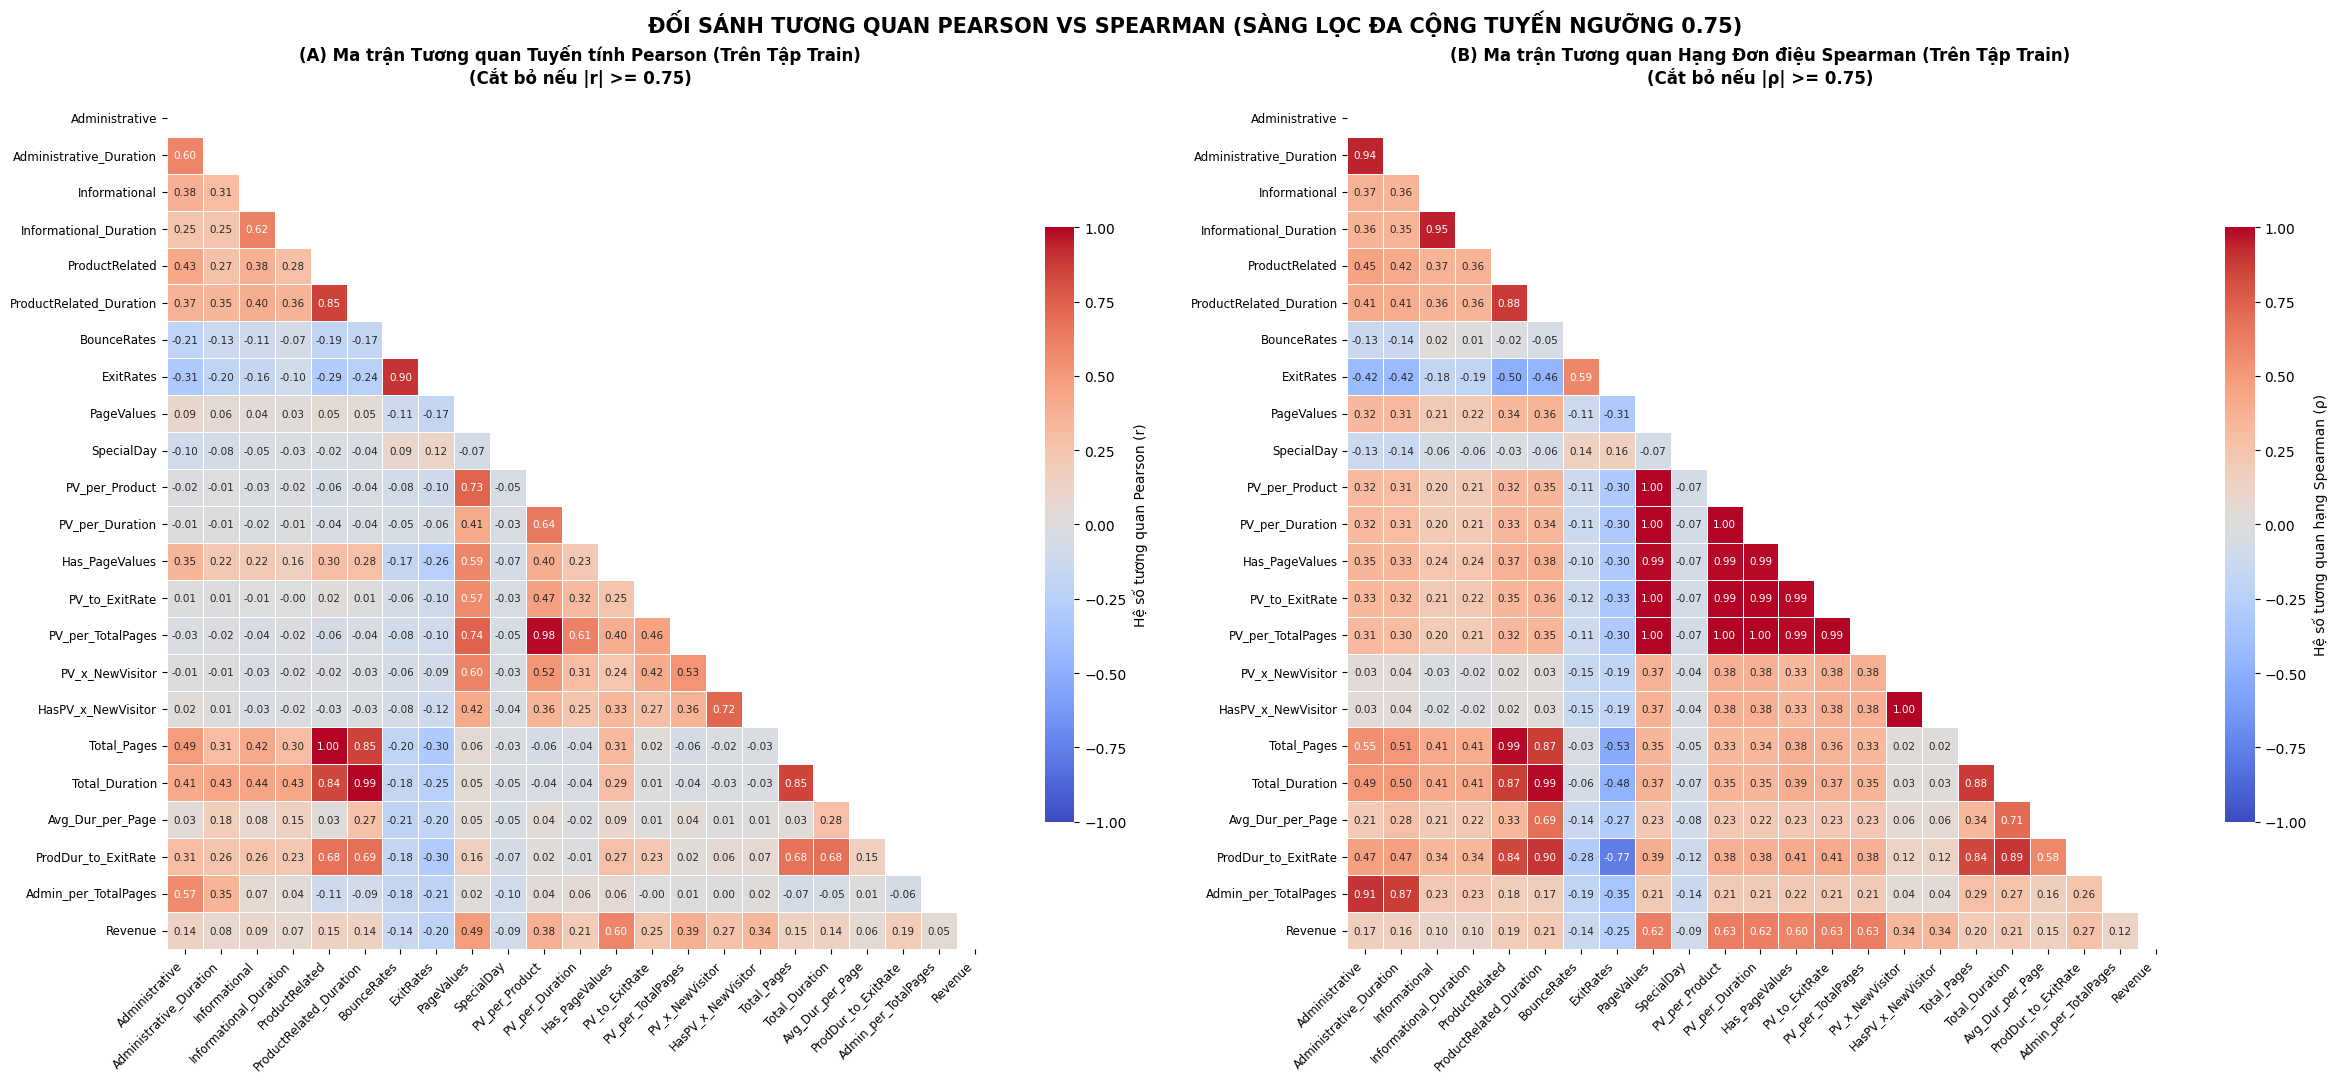

In [4]:
# 1. Tính toán ma trận tương quan Pearson và Spearman CHỈ TRÊN TẬP TRAIN (Không chạm Test)
orig_numeric = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

candidate_numeric = [
    'PV_per_Product', 'PV_per_Duration', 'Has_PageValues',
    'PV_to_ExitRate', 'PV_per_TotalPages', 'PV_x_NewVisitor', 'HasPV_x_NewVisitor',
    'Total_Pages', 'Total_Duration', 'Avg_Dur_per_Page', 'ProdDur_to_ExitRate', 'Admin_per_TotalPages'
]

all_corr_features = orig_numeric + candidate_numeric + ['Revenue']
df_corr_train = X_train[orig_numeric + candidate_numeric].copy()
df_corr_train['Revenue'] = y_train.values

corr_pearson = df_corr_train.corr(method='pearson')
corr_spearman = df_corr_train.corr(method='spearman')

# Lưu kết quả ra file CSV
corr_pearson.round(2).to_csv('corr_pearson_full.csv')
corr_spearman.round(2).to_csv('corr_spearman_full.csv')
print("-> Đã lưu ma trận tương quan (tính trên tập Train) vào corr_pearson_full.csv và corr_spearman_full.csv")

# 2. Thiết lập ngưỡng tương quan & Quét các cặp biến đa cộng tuyến
CORR_THRESHOLD = 0.75
print(f"\n-> Ngưỡng lọc tương quan được thiết lập: CORR_THRESHOLD = {CORR_THRESHOLD}")

# Quét các cặp biến có |Pearson| >= CORR_THRESHOLD hoặc |Spearman| >= CORR_THRESHOLD
high_corr_detected = []
checked_pairs = set()

for feat_cand in candidate_numeric:
    for feat_target in (orig_numeric + candidate_numeric):
        if feat_cand == feat_target:
            continue
        pair_key = tuple(sorted([feat_cand, feat_target]))
        if pair_key in checked_pairs:
            continue
        checked_pairs.add(pair_key)

        r_val = corr_pearson.loc[feat_cand, feat_target]
        rho_val = corr_spearman.loc[feat_cand, feat_target]

        # Bỏ qua cụm biến tỷ lệ nội bộ cùng dẫn xuất từ PageValues vì 80% PV=0 làm Spearman bằng 1.0
        pv_group = {'Has_PageValues', 'PV_to_ExitRate', 'PV_per_TotalPages', 'PV_per_Duration', 'PV_per_Product', 'PageValues'}
        is_internal_pv = (feat_cand in pv_group and feat_target in pv_group)

        # Tiêu chuẩn: Pearson >= 0.75 hoặc (Spearman >= 0.75 và không phải cặp nội bộ PV zero-inflated)
        if abs(r_val) >= CORR_THRESHOLD or (abs(rho_val) >= CORR_THRESHOLD and not is_internal_pv):
            high_corr_detected.append({
                'X': feat_cand,
                'Y': feat_target,
                'Pearson': round(r_val, 2),
                'Spearman': round(rho_val, 2),
                'Corr(X, Revenue)': round(corr_pearson.loc[feat_cand, 'Revenue'], 2),
                'Corr(Y, Revenue)': round(corr_pearson.loc[feat_target, 'Revenue'], 2)
            })

df_high_corr = pd.DataFrame(high_corr_detected)
print(f"\n=== CÁC CẶP BIẾN ĐA CỘNG TUYẾN VƯỢT NGƯỠNG (|r| hoặc |ρ| >= {CORR_THRESHOLD}) ===")
display(df_high_corr)

# 3. Trực quan hóa đối sánh Pearson vs Spearman trong cùng 1 plot (2 subplots)
fig, axes = plt.subplots(1, 2, figsize=(24, 11))
mask_p = np.triu(np.ones_like(corr_pearson, dtype=bool))
mask_s = np.triu(np.ones_like(corr_spearman, dtype=bool))

sns.heatmap(
    corr_pearson, mask=mask_p, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 7.5},
    cbar_kws={'shrink': 0.7, 'label': 'Hệ số tương quan Pearson (r)'}, ax=axes[0]
)
axes[0].set_title(f'(A) Ma trận Tương quan Tuyến tính Pearson (Trên Tập Train)\n(Cắt bỏ nếu |r| >= {CORR_THRESHOLD})', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right', fontsize=8.5)
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0, fontsize=8.5)

sns.heatmap(
    corr_spearman, mask=mask_s, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 7.5},
    cbar_kws={'shrink': 0.7, 'label': 'Hệ số tương quan hạng Spearman (ρ)'}, ax=axes[1]
)
axes[1].set_title(f'(B) Ma trận Tương quan Hạng Đơn điệu Spearman (Trên Tập Train)\n(Cắt bỏ nếu |ρ| >= {CORR_THRESHOLD})', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right', fontsize=8.5)
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=8.5)

plt.suptitle(f'ĐỐI SÁNH TƯƠNG QUAN PEARSON VS SPEARMAN (SÀNG LỌC ĐA CỘNG TUYẾN NGƯỠNG {CORR_THRESHOLD})', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('corr_pearson_vs_spearman_full.png', dpi=300, bbox_inches='tight')
plt.show()


## 2. Thiết lập Lộ trình Thử nghiệm & Pipeline Đánh giá 12-Fold Cross-Validation

### 2.1. Bảng Quyết định Loại bỏ Biến sau Sàng lọc Tương quan (`CORR_THRESHOLD = 0.75`)

| Removed Feature | New Feature | Reason |
| :--- | :---: | :--- |
| **`Total_Pages`** | `True` | `Pearson = 1.00`, `Spearman = 0.99` với biến gốc `ProductRelated` (`Corr(Revenue)`: `0.15` vs `0.15`) $\rightarrow$ Giữ biến gốc `ProductRelated`. |
| **`Total_Duration`** | `True` | `Pearson = 0.99`, `Spearman = 0.99` với biến gốc `ProductRelated_Duration` (`Corr(Revenue)`: `0.14` vs `0.14`) $\rightarrow$ Giữ biến gốc `ProductRelated_Duration`. |
| **`PV_per_Product`** | `True` | `Pearson = 0.98`, `Spearman = 1.00` với `PV_per_TotalPages`, nhưng `Corr(Revenue)` thấp hơn (`0.38 < 0.39`) $\rightarrow$ Giữ `PV_per_TotalPages`. |
| **`HasPV_x_NewVisitor`** | `True` | `Spearman = 1.00`, `Pearson = 0.72` (sau `log1p`: `0.98`) với `PV_x_NewVisitor`; chỉ mang giá trị nhị phân $0/1$ làm mất biên độ liên tục $\rightarrow$ Giữ `PV_x_NewVisitor`. |
| **`Month_x_Weekend`, `Month_x_Visitor`, `Traffic_x_Visitor`** | `True` | Làm tăng số chiều One-Hot Encoding nhưng đóng góp cận biên không đáng kể $\rightarrow$ Chỉ giữ `Month_x_HasPV`. |
| *(17 biến gốc)* | `False` | **Không loại bỏ biến gốc nào**. *(Ghi chú: `ProdDur_to_ExitRate` và `Admin_per_TotalPages` có `Spearman >= 0.75` do đồng hạng tại $0$, nhưng `Pearson = 0.30 - 0.69 < 0.75` nên được giữ lại).* |

---

### 2.2. Bảng Thiết kế Lộ trình Thử nghiệm (4 Bước FE):

| Giai đoạn | Cấu hình Thử nghiệm | Số biến | Thành phần kế thừa | Đặc trưng bổ sung (Đã qua sàng lọc tương quan) |
| :---: | :--- | :---: | :--- | :--- |
| **Exp 0** | **`Raw OHE (Baseline)`** | **17** | 17 biến gốc thô | Passthrough 10 biến số, One-Hot Encoding 7 biến phân loại. |
| **Exp 1** | **`StandardScaler`** | **17** | 17 biến gốc | `StandardScaler` toàn bộ 10 biến số, OHE 7 biến phân loại. |
| **Exp 1** | **`Log1p + StandardScaler`** *(Base 17)* | **17** | 17 biến gốc | `np.log1p` cho 5 biến lệch nặng + `StandardScaler` 10 biến số + OHE 7 biến phân loại. **(Mốc đối chiếu chuẩn Base 17)** |
| **Exp 3** | **`2. FE1 (Core PV Density)`** | **20** | Base (Full 17) | **+ 3 biến**: `Has_PageValues`, `PV_per_TotalPages`, `PV_per_Duration` |
| **Exp 3** | **`3. FE2 (Value vs. Friction)`** | **22** | Kế thừa `FE1` | **+ 2 biến**: `PV_to_ExitRate`, `PV_x_NewVisitor` |
| **Exp 3** | **`4. FE3 (Non-PV Engagement)`** | **25** | Kế thừa `FE2` | **+ 3 biến**: `ProdDur_to_ExitRate`, `Avg_Dur_per_Page`, `Admin_per_TotalPages` |
| **Exp 3** | **`5. FE4 (Seasonality Context)`** | **26** | Kế thừa `FE3` | **+ 1 biến**: `Month_x_HasPV` *(Hoàn thiện 9 biến mới tinh gọn)* |

In [5]:
# 1. Định nghĩa 4 bước cấu hình FE tinh gọn sau khi đã sàng lọc tương quan
FE1_COLS = ['Has_PageValues', 'PV_per_TotalPages', 'PV_per_Duration']
FE2_COLS = FE1_COLS + ['PV_to_ExitRate', 'PV_x_NewVisitor']
FE3_COLS = FE2_COLS + ['ProdDur_to_ExitRate', 'Avg_Dur_per_Page', 'Admin_per_TotalPages']
FE4_COLS = FE3_COLS + ['Month_x_HasPV']

FEATURE_CONFIGS = {
    '1. log1p_Zscore': FULL17_FEATS,
    '2. FE1': FULL17_FEATS + FE1_COLS,
    '3. FE2': FULL17_FEATS + FE2_COLS,
    '4. FE3': FULL17_FEATS + FE3_COLS,
    '5. FE4': FULL17_FEATS + FE4_COLS,
}

print("=== DANH SÁCH CẤU HÌNH THỬ NGHIỆM SAU SÀNG LỌC TƯƠNG QUAN ===")
for name, f_list in FEATURE_CONFIGS.items():
    print(f"   * {name:32}: {len(f_list):2d} đặc trưng")

# 2. Phân loại danh mục đặc trưng cho Pipeline tiền xử lý
LOG_COLS_ALL = [
    'Administrative', 'Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues',
    'PV_per_TotalPages', 'PV_per_Duration', 'PV_to_ExitRate', 'PV_x_NewVisitor',
    'ProdDur_to_ExitRate', 'Avg_Dur_per_Page'
]
NUM_COLS_ALL = [
    'Informational', 'Informational_Duration', 'BounceRates', 'ExitRates', 'SpecialDay',
    'Has_PageValues', 'Admin_per_TotalPages'
]
CAT_COLS_ALL = [
    'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend',
    'Month_x_HasPV'
]

rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
scorers = get_cv_scorers()

def build_preprocessor(feats):
    curr_log = [c for c in LOG_COLS_ALL if c in feats]
    curr_num = [c for c in NUM_COLS_ALL if c in feats]
    curr_cat = [c for c in CAT_COLS_ALL if c in feats]

    transformers = []
    if curr_log:
        transformers.append(('log_scale', Pipeline([
            ('log', FunctionTransformer(np.log1p, validate=True)),
            ('sc', StandardScaler())
        ]), curr_log))
    if curr_num:
        transformers.append(('num_scale', StandardScaler(), curr_num))
    if curr_cat:
        transformers.append(('cat_ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), curr_cat))

    return ColumnTransformer(transformers=transformers)

def build_pipeline(feats, model_name):
    pre = build_preprocessor(feats)
    if model_name == 'LR':
        clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    elif model_name == 'XGBoost':
        clf = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)
    else:
        raise ValueError(f"Unknown model_name {model_name}")
    return Pipeline([('prep', pre), ('clf', clf)])

# Xóa các log thực nghiệm cũ của exp3 trong experiment_results.json để ghi đè sạch sẽ
if os.path.exists('experiment_results.json'):
    with open('experiment_results.json', 'r', encoding='utf-8') as f:
        exp_data = json.load(f)
    exp_data = {k: v for k, v in exp_data.items() if not k.startswith('exp3_')}
    with open('experiment_results.json', 'w', encoding='utf-8') as f:
        json.dump(exp_data, f, indent=2, ensure_ascii=False)

cv_results_store = {}

print(f"\nĐang chạy 12-Fold CV cho {len(FEATURE_CONFIGS)} cấu hình trên 3 mô hình (LR, XGBoost & MLP)...")
print(f"-> Thiết bị tính toán cho MLP: {DEVICE}")

for cfg_name, feats in FEATURE_CONFIGS.items():
    pre = build_preprocessor(feats)
    for model_name in ['LR', 'XGBoost', 'MLP']:
        if model_name in ['LR', 'XGBoost']:
            pipe = build_pipeline(feats, model_name)
            out = cross_validate(pipe, X_train[feats], y_train, cv=rskf, scoring=scorers, n_jobs=-1)
        else: # MLP: Tái sử dụng hàm cross_validate_mlp từ logger.py
            out = cross_validate_mlp(X_train[feats], y_train, pre, rskf, random_state=RANDOM_STATE)

        cv_results_store[(cfg_name, model_name)] = out

        slug = 'Base_Full17' if ('Base' in cfg_name or 'log1p' in cfg_name) else cfg_name.split('(')[0].replace('.', '').strip().replace(' ', '_')
        exp_id = f"exp3_{slug}_{model_name}"
        log_experiment(
            exp_id=exp_id,
            model_name=model_name if model_name != 'MLP' else 'MLP (PyTorch)',
            notebook=NOTEBOOK,
            description=f"Exp3 Base 17 | {cfg_name}",
            config={'features_count': len(feats), 'features': feats, 'cv': f'{N_SPLITS}x{N_REPEATS}', 'threshold': THRESHOLD},
            cv_results=out,
            threshold=THRESHOLD
        )
print("-> Hoàn tất 12-Fold CV thành công cho cả 3 mô hình!")


=== DANH SÁCH CẤU HÌNH THỬ NGHIỆM SAU SÀNG LỌC TƯƠNG QUAN ===
   * 1. log1p_Zscore                 : 17 đặc trưng
   * 2. FE1                          : 20 đặc trưng
   * 3. FE2                          : 22 đặc trưng
   * 4. FE3                          : 25 đặc trưng
   * 5. FE4                          : 26 đặc trưng

Đang chạy 12-Fold CV cho 5 cấu hình trên 3 mô hình (LR, XGBoost & MLP)...
-> Thiết bị tính toán cho MLP: cuda
-> Đã lưu thành công thực nghiệm 'exp3_Base_Full17_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_Base_Full17_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_Base_Full17_MLP' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_2_FE1_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_2_FE1_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_2_FE1_MLP' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_3_FE2_LR' vào experiment_results.jso

## 3. Bảng Kết quả 12-Fold Cross-Validation & Kiểm định Hiệu năng Cặp (Paired Differences vs. Base)

- Trình bày đầy đủ các chỉ số chuẩn hóa theo `huong_dan_danh_gia_mo_hinh.md` dưới dạng `mean ± std` (% với 2 chữ số thập phân) tại ngưỡng mặc định `threshold = 0.50`:
  - `CV AP (%)` *(Độ đo chính)*
  - `ΔAP (vs Base)` kèm kiểm định $t$-test cặp (`p-value`, số fold thắng trên 12 folds) và `Sai số chuẩn (SE)` của hiệu số.
  - `CV Precision (Mua) (%)`, `CV Recall (Mua) (%)`, `CV F1 (Mua) (%)` cho lớp `1 = Mua`.
  - `CV F1 (Không mua) (%)` và `CV F1 macro (%)`.

In [6]:
paired_rows = []
base_cfg_name = list(FEATURE_CONFIGS.keys())[0]

for model in ['XGBoost', 'LR', 'MLP']:
    base_ap = cv_results_store[(base_cfg_name, model)]['test_ap'] * 100

    for cfg_name, feats in FEATURE_CONFIGS.items():
        res = cv_results_store[(cfg_name, model)]
        ap = res['test_ap'] * 100
        diff_base = ap - base_ap

        p1_arr = res['test_prec_1'] * 100
        r1_arr = res['test_rec_1'] * 100
        f1_1_arr = res['test_f1_1'] * 100
        f1_0_arr = res['test_f1_0'] * 100
        f1_macro_arr = (res['test_f1_macro'] * 100) if 'test_f1_macro' in res else ((f1_0_arr + f1_1_arr) / 2)

        se_base = diff_base.std(ddof=1) / np.sqrt(len(diff_base)) if cfg_name != base_cfg_name else 0.0
        p_base = stats.ttest_1samp(diff_base, 0).pvalue if cfg_name != base_cfg_name else 1.0

        paired_rows.append({
            'Mô hình': model if model != 'MLP' else 'MLP (PyTorch)',
            'Cấu hình': cfg_name,
            'Số biến': len(feats),
            'CV AP (%)': f"{ap.mean():.2f} ± {ap.std():.2f}",
            f'ΔAP (vs {base_cfg_name})': '-' if cfg_name == base_cfg_name else f"{diff_base.mean():+.2f}% (p={p_base:.4f}, {(diff_base>0).sum()}/12)",
            'Sai số chuẩn (SE)': f"{se_base:.2f}" if cfg_name != base_cfg_name else '-',
            'CV Precision (Mua) (%)': f"{p1_arr.mean():.2f} ± {p1_arr.std():.2f}",
            'CV Recall (Mua) (%)': f"{r1_arr.mean():.2f} ± {r1_arr.std():.2f}",
            'CV F1 (Mua) (%)': f"{f1_1_arr.mean():.2f} ± {f1_1_arr.std():.2f}",
            'CV F1 (Không mua) (%)': f"{f1_0_arr.mean():.2f} ± {f1_0_arr.std():.2f}",
            'CV F1 macro (%)': f"{f1_macro_arr.mean():.2f} ± {f1_macro_arr.std():.2f}"
        })

paired_df = pd.DataFrame(paired_rows)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 300)
print(f"=== BẢNG KẾT QUẢ 12-FOLD CROSS-VALIDATION (Ngưỡng phân loại threshold = {THRESHOLD:.2f}) ===")
display(paired_df)


=== BẢNG KẾT QUẢ 12-FOLD CROSS-VALIDATION (Ngưỡng phân loại threshold = 0.50) ===


,Mô hình,Cấu hình,Số biến,CV AP (%),ΔAP (vs 1. log1p_Zscore),Sai số chuẩn (SE),CV Precision (Mua) (%),CV Recall (Mua) (%),CV F1 (Mua) (%),CV F1 (Không mua) (%),CV F1 macro (%)
0,XGBoost,1. log1p_Zscore,17,71.70 ± 1.97,-,-,69.67 ± 3.07,58.19 ± 1.60,63.37 ± 1.50,93.86 ± 0.36,78.61 ± 0.92
1,XGBoost,2. FE1,20,71.18 ± 1.90,"-0.52% (p=0.0417, 3/12)",0.22,69.94 ± 2.78,58.32 ± 2.93,63.53 ± 2.02,93.90 ± 0.36,78.71 ± 1.16
2,XGBoost,3. FE2,22,72.08 ± 1.77,"+0.38% (p=0.1725, 9/12)",0.26,69.56 ± 2.75,58.65 ± 2.40,63.59 ± 1.74,93.87 ± 0.35,78.73 ± 1.02
3,XGBoost,4. FE3,25,72.00 ± 1.87,"+0.30% (p=0.3088, 9/12)",0.28,70.04 ± 2.86,58.32 ± 2.39,63.60 ± 1.94,93.91 ± 0.37,78.75 ± 1.13
4,XGBoost,5. FE4,26,72.24 ± 1.69,"+0.54% (p=0.0994, 7/12)",0.30,70.49 ± 2.38,58.76 ± 2.32,64.06 ± 1.81,93.99 ± 0.32,79.02 ± 1.05
5,LR,1. log1p_Zscore,17,68.15 ± 2.07,-,-,70.40 ± 2.64,55.11 ± 2.12,61.79 ± 1.82,93.81 ± 0.33,77.80 ± 1.05
6,LR,2. FE1,20,71.33 ± 2.24,"+3.18% (p=0.0000, 12/12)",0.22,71.37 ± 2.69,58.11 ± 2.50,64.03 ± 2.24,94.06 ± 0.38,79.04 ± 1.30
7,LR,3. FE2,22,71.99 ± 1.99,"+3.85% (p=0.0000, 12/12)",0.26,72.15 ± 3.17,57.91 ± 2.55,64.21 ± 2.38,94.13 ± 0.42,79.17 ± 1.39
8,LR,4. FE3,25,72.24 ± 1.98,"+4.10% (p=0.0000, 12/12)",0.28,72.22 ± 3.12,58.35 ± 2.75,64.49 ± 2.22,94.15 ± 0.39,79.32 ± 1.28
9,LR,5. FE4,26,73.22 ± 1.80,"+5.07% (p=0.0000, 12/12)",0.26,71.88 ± 2.21,58.74 ± 2.94,64.56 ± 1.48,94.13 ± 0.22,79.35 ± 0.81


## 4. Chẩn đoán Hiệu năng Phân khúc $PV = 0$ vs. $PV > 0$ (Out-of-Fold trên Tập Train)

Nhằm tuân thủ tuyệt đối nguyên tắc **không chạm vào tập Test Hold-out** trong quá trình phân tích và chẩn đoán mô hình:
- **Đánh giá xác suất dự đoán Out-of-Fold (OOF)**: Sử dụng `StratifiedKFold(n_splits=4)` trên tập `X_train` để sinh xác suất dự đoán khách quan cho toàn bộ 9,764 phiên.
- **Tách phân khúc đánh giá**:
  - **Nhóm $PV = 0$** (Vùng mù hành vi, chiếm ~80% phiên): Tỷ lệ mua thực tế chỉ 3.93%. Khảo sát AP và F1 (lớp Mua) tại ngưỡng mặc định `threshold = 0.50` và ngưỡng nhạy `threshold = 0.30`.
  - **Nhóm $PV > 0$** (Phân khúc có giá trị trang, chiếm ~20% phiên): Tỷ lệ mua thực tế 56.15%.

In [7]:
# Chẩn đoán Phân khúc PV = 0 vs PV > 0 bằng Out-of-Fold (OOF) trên Tập Train
from sklearn.model_selection import StratifiedKFold
skf_oof = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
mask_train_pv0 = (X_train['PageValues'] == 0).values
mask_train_pv_pos = (X_train['PageValues'] > 0).values

subgroup_rows = []
for model_name in ['XGBoost', 'LR', 'MLP']:
    for cfg_name, feats in FEATURE_CONFIGS.items():
        if model_name in ['XGBoost', 'LR']:
            pipe = build_pipeline(feats, model_name)
            oof_proba = cross_val_predict(pipe, X_train[feats], y_train, cv=skf_oof, method='predict_proba', n_jobs=-1)[:, 1]
        else: # MLP
            oof_proba = np.zeros(len(y_train))
            pre = build_preprocessor(feats)
            for tr_idx, val_idx in skf_oof.split(X_train[feats], y_train):
                prep_f, model_f = train_pytorch_mlp(X_train[feats].iloc[tr_idx], y_train.iloc[tr_idx], pre, random_state=RANDOM_STATE)
                oof_proba[val_idx] = predict_proba_mlp(prep_f, model_f, X_train[feats].iloc[val_idx])

        ap_total = average_precision_score(y_train, oof_proba) * 100
        ap_pv0 = average_precision_score(y_train[mask_train_pv0], oof_proba[mask_train_pv0]) * 100
        ap_pv_pos = average_precision_score(y_train[mask_train_pv_pos], oof_proba[mask_train_pv_pos]) * 100

        # Đánh giá F1 của nhãn Mua (lớp 1) tại ngưỡng 0.50 và 0.30
        pred_pv0_50 = (oof_proba[mask_train_pv0] >= 0.50).astype(int)
        f1_pv0_50 = f1_score(y_train[mask_train_pv0], pred_pv0_50, zero_division=0) * 100

        pred_pv0_30 = (oof_proba[mask_train_pv0] >= 0.30).astype(int)
        f1_pv0_30 = f1_score(y_train[mask_train_pv0], pred_pv0_30, zero_division=0) * 100

        display_cfg = cfg_name.split('.')[1].strip() if '.' in cfg_name else cfg_name

        subgroup_rows.append({
            'Mô hình': model_name if model_name != 'MLP' else 'MLP (PyTorch)',
            'Cấu hình': display_cfg,
            'OOF AP Toàn tập (%)': f"{ap_total:.2f}%",
            'OOF AP (PV=0) (%)': f"{ap_pv0:.2f}%",
            'OOF AP (PV>0) (%)': f"{ap_pv_pos:.2f}%",
            'F1 (Mua) (PV=0, @0.5) (%)': f"{f1_pv0_50:.2f}%",
            'F1 (Mua) (PV=0, @0.3) (%)': f"{f1_pv0_30:.2f}%"
        })

df_subgroup = pd.DataFrame(subgroup_rows)
print("=== CHẨN ĐOÁN HIỆU NĂNG PHÂN KHÚC PV = 0 VS. PV > 0 (TRÊN OUT-OF-FOLD TẬP TRAIN) ===")
display(df_subgroup)


=== CHẨN ĐOÁN HIỆU NĂNG PHÂN KHÚC PV = 0 VS. PV > 0 (TRÊN OUT-OF-FOLD TẬP TRAIN) ===


,Mô hình,Cấu hình,OOF AP Toàn tập (%),OOF AP (PV=0) (%),OOF AP (PV>0) (%),"F1 (Mua) (PV=0, @0.5) (%)","F1 (Mua) (PV=0, @0.3) (%)"
0,XGBoost,log1p_Zscore,70.85%,15.81%,79.38%,8.47%,15.28%
1,XGBoost,FE1,70.46%,16.38%,78.77%,8.80%,13.49%
2,XGBoost,FE2,71.78%,15.87%,80.41%,7.54%,14.80%
3,XGBoost,FE3,71.57%,17.10%,79.94%,10.29%,13.51%
4,XGBoost,FE4,72.29%,16.57%,80.64%,8.16%,12.84%
5,LR,log1p_Zscore,67.88%,12.47%,75.13%,0.00%,0.00%
6,LR,FE1,71.00%,11.93%,78.73%,0.00%,0.00%
7,LR,FE2,71.75%,12.58%,79.52%,0.00%,0.00%
8,LR,FE3,71.99%,17.37%,79.34%,1.33%,5.08%
9,LR,FE4,73.01%,18.72%,80.31%,1.33%,7.34%


## 5. Đánh giá Kiểm chứng Toàn diện trên Tập Test Hold-out (Độc lập)

Sau khi hoàn tất sàng lọc tương quan và đánh giá trên 12-Fold CV, toàn bộ 5 cấu hình được huấn luyện lại trên toàn bộ `X_train` và kiểm chứng độc lập trên tập `X_test` ($2,441$ phiên):
- Báo cáo đầy đủ theo `huong_dan_danh_gia_mo_hinh.md` tại ngưỡng quyết định `threshold = 0.50`:
  - **Độ đo chính**: `Test AP (%)` (`average_precision_score`) và mức chênh lệch `ΔAP (vs Base)`.
  - **Độ đo theo lớp**: `Precision (Mua) (%)`, `Recall (Mua) (%)`, `F1 (Mua) (%)` cho lớp `1 = Mua`; cùng `F1 (Không mua) (%)` cho lớp `0 = Không mua` và `F1 macro (%)`.
  - **Báo cáo chi tiết (`classification_report`)** với nhãn chuẩn `0 = Không mua`, `1 = Mua`.
  - **Trực quan hóa Ma trận Nhầm lẫn (`confusion_matrix`)**: Hiển thị trực tiếp trên notebook cho cả 5 cấu hình $\times$ 2 mô hình *(tuyệt đối không lưu `confusion_matrix` vào file `experiment_results.json`)*.
  - **Đường cong Precision-Recall (`precision_recall_curve`)**: Khảo sát sự đánh đổi giữa Precision và Recall.

Đang huấn luyện trên toàn bộ X_train và đánh giá độc lập trên X_test (2,441 phiên)...
-> Đã lưu thành công thực nghiệm 'exp3_TEST_Base_Full17_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_2_FE1_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_3_FE2_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_4_FE3_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_5_FE4_XGBoost' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_Base_Full17_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_2_FE1_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_3_FE2_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_4_FE3_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_5_FE4_LR' vào experiment_results.json
-> Đã lưu thành công thực nghiệm 'exp3_TEST_Base_Full17_M

,Mô hình,Cấu hình,Số biến,Test AP (%),ΔAP (vs 1. log1p_Zscore),Precision (Mua) (%),Recall (Mua) (%),F1 (Mua) (%),F1 (Không mua) (%),F1 macro (%),Accuracy (%),Test AP (PV = 0) (%)
0,XGBoost,1. log1p_Zscore,17,72.42,-,68.06,59.69,63.60,93.73,78.67,89.31,16.83
1,XGBoost,2. FE1,20,71.34,-1.08%,69.10,62.04,65.38,93.96,79.67,89.72,14.60
2,XGBoost,3. FE2,22,72.40,-0.02%,69.01,61.78,65.19,93.94,79.57,89.68,15.93
3,XGBoost,4. FE3,25,73.49,+1.07%,71.99,62.57,66.95,94.34,80.64,90.33,16.12
4,XGBoost,5. FE4,26,71.32,-1.10%,70.18,60.99,65.27,94.05,79.66,89.84,14.53
5,LR,1. log1p_Zscore,17,69.52,-,71.84,59.42,65.04,94.17,79.61,90.00,15.26
6,LR,2. FE1,20,72.35,+2.83%,71.78,61.26,66.10,94.25,80.18,90.17,15.43
7,LR,3. FE2,22,73.10,+3.58%,71.74,60.47,65.62,94.21,79.92,90.09,16.60
8,LR,4. FE3,25,73.53,+4.01%,71.69,60.99,65.91,94.23,80.07,90.13,20.09
9,LR,5. FE4,26,74.40,+4.88%,74.36,60.73,66.86,94.51,80.68,90.58,21.81



=== CLASSIFICATION REPORT CHI TIẾT TRÊN TẬP TEST (0 = Không mua, 1 = Mua | Threshold = 0.50) ===

--- Mô hình: XGBoost | Cấu hình: 1. log1p_Zscore | Test AP: 72.42% ---
               precision    recall  f1-score   support

0 = Không mua     0.9269    0.9480    0.9373      2059
      1 = Mua     0.6806    0.5969    0.6360       382

     accuracy                         0.8931      2441
    macro avg     0.8037    0.7724    0.7867      2441
 weighted avg     0.8883    0.8931    0.8902      2441


--- Mô hình: XGBoost | Cấu hình: 5. FE4 | Test AP: 71.32% ---
               precision    recall  f1-score   support

0 = Không mua     0.9294    0.9519    0.9405      2059
      1 = Mua     0.7018    0.6099    0.6527       382

     accuracy                         0.8984      2441
    macro avg     0.8156    0.7809    0.7966      2441
 weighted avg     0.8937    0.8984    0.8955      2441


--- Mô hình: LR | Cấu hình: 1. log1p_Zscore | Test AP: 69.52% ---
               precision    recall

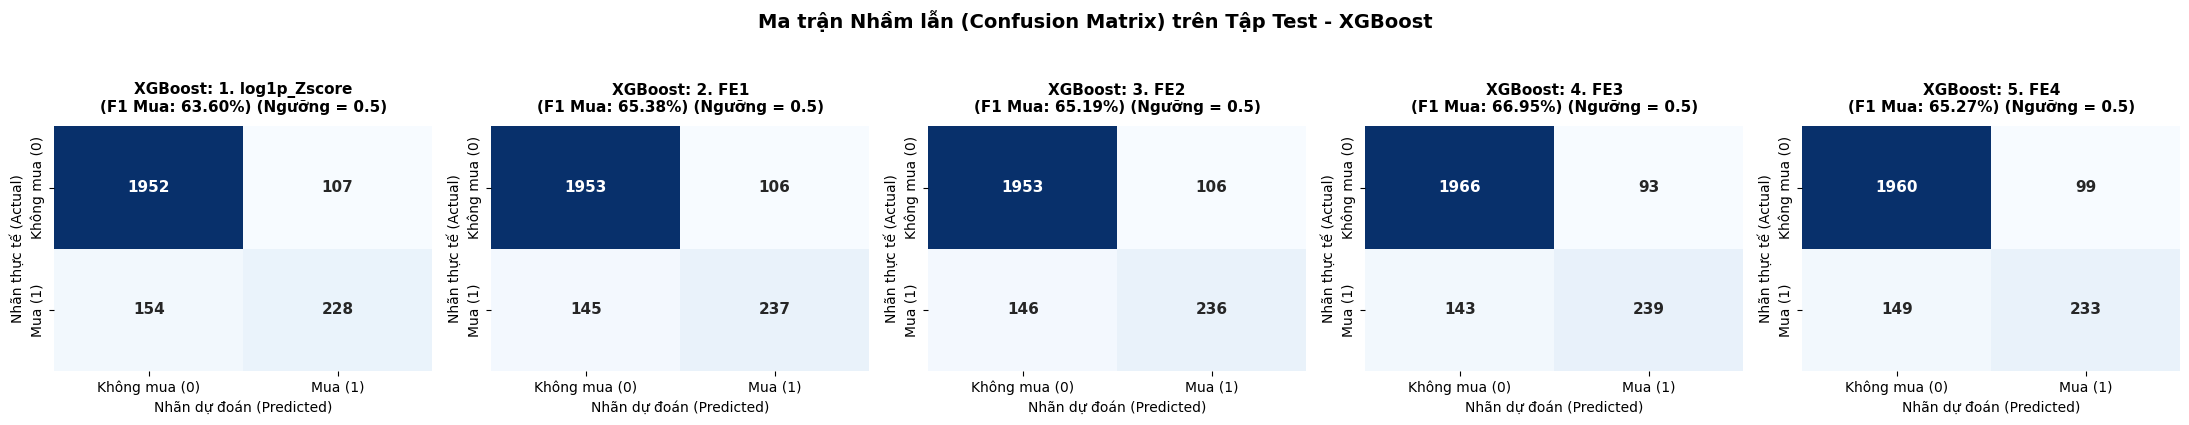

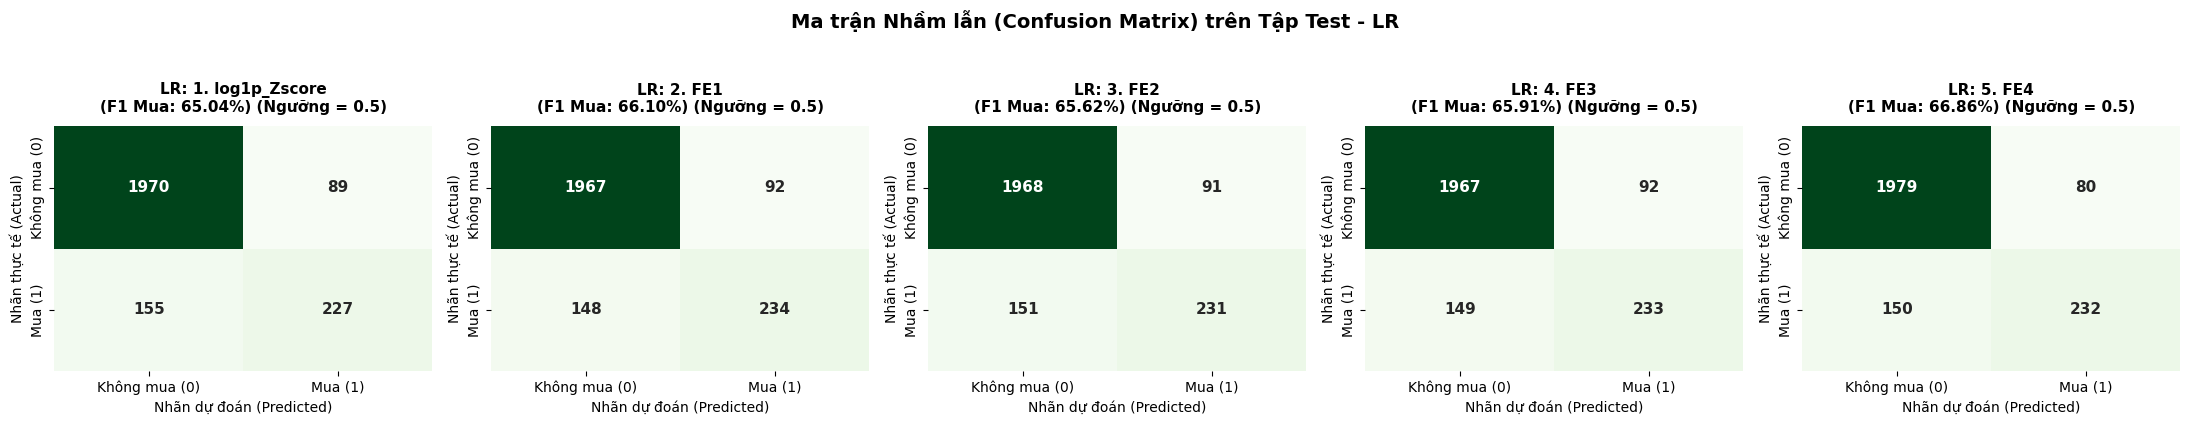

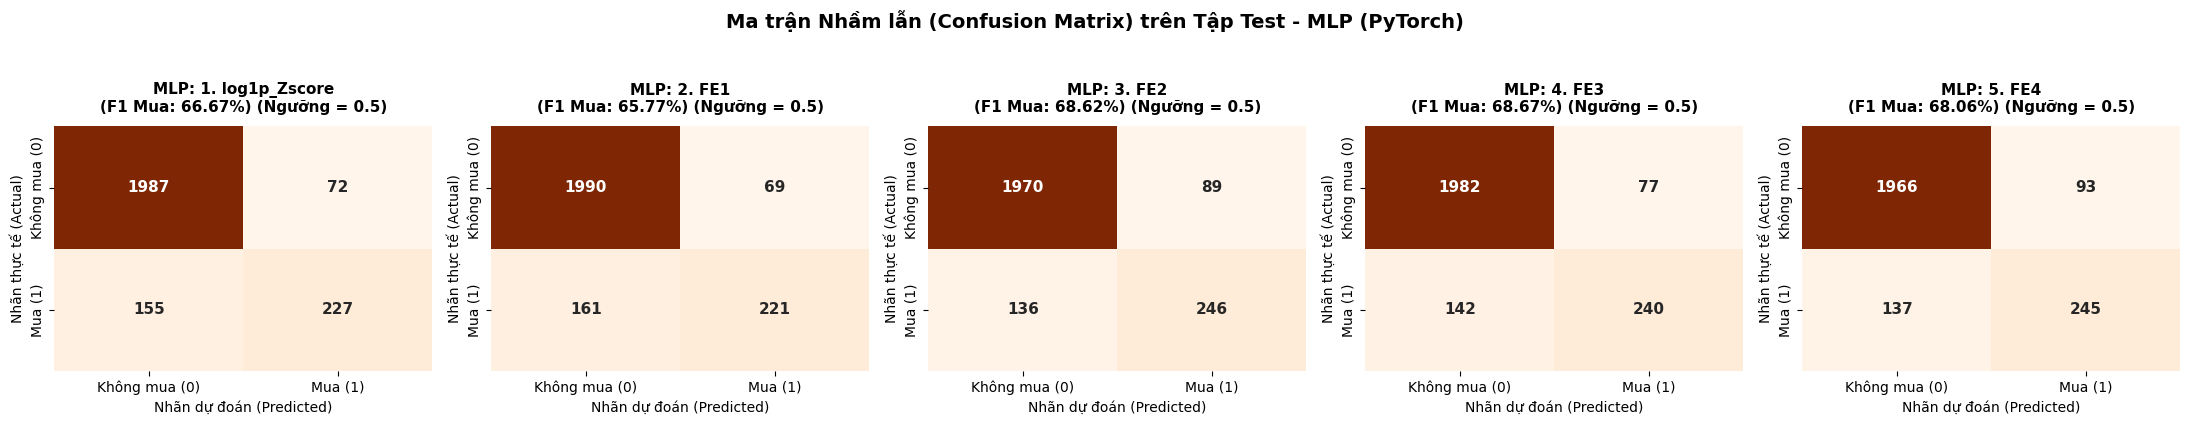

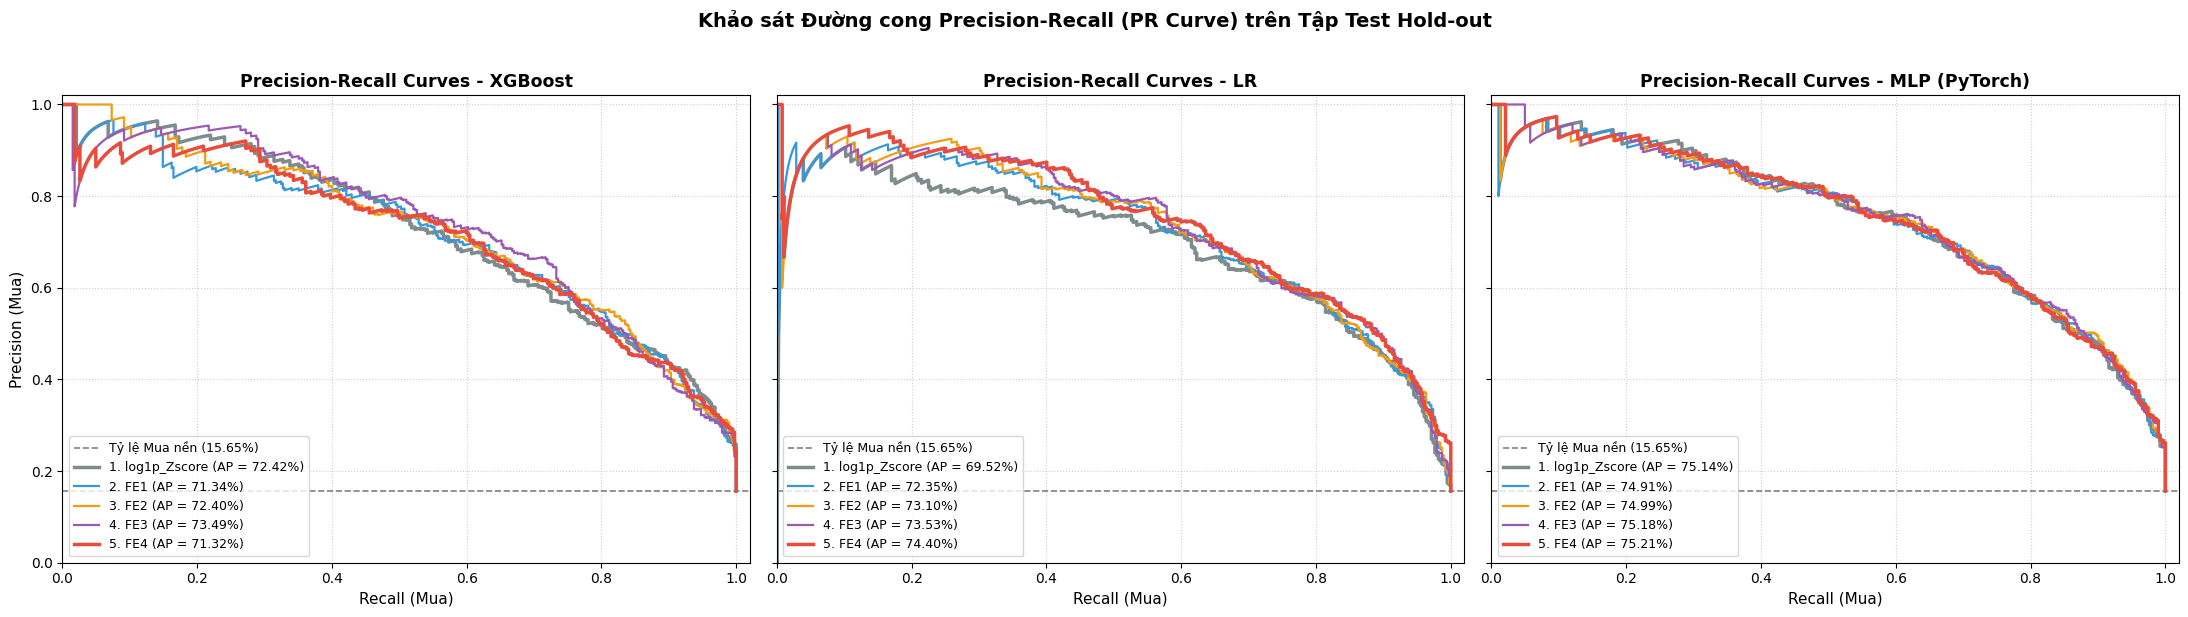


TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) - PYTORCH MLP TRÊN TẬP TRAIN & VAL NỘI BỘ:


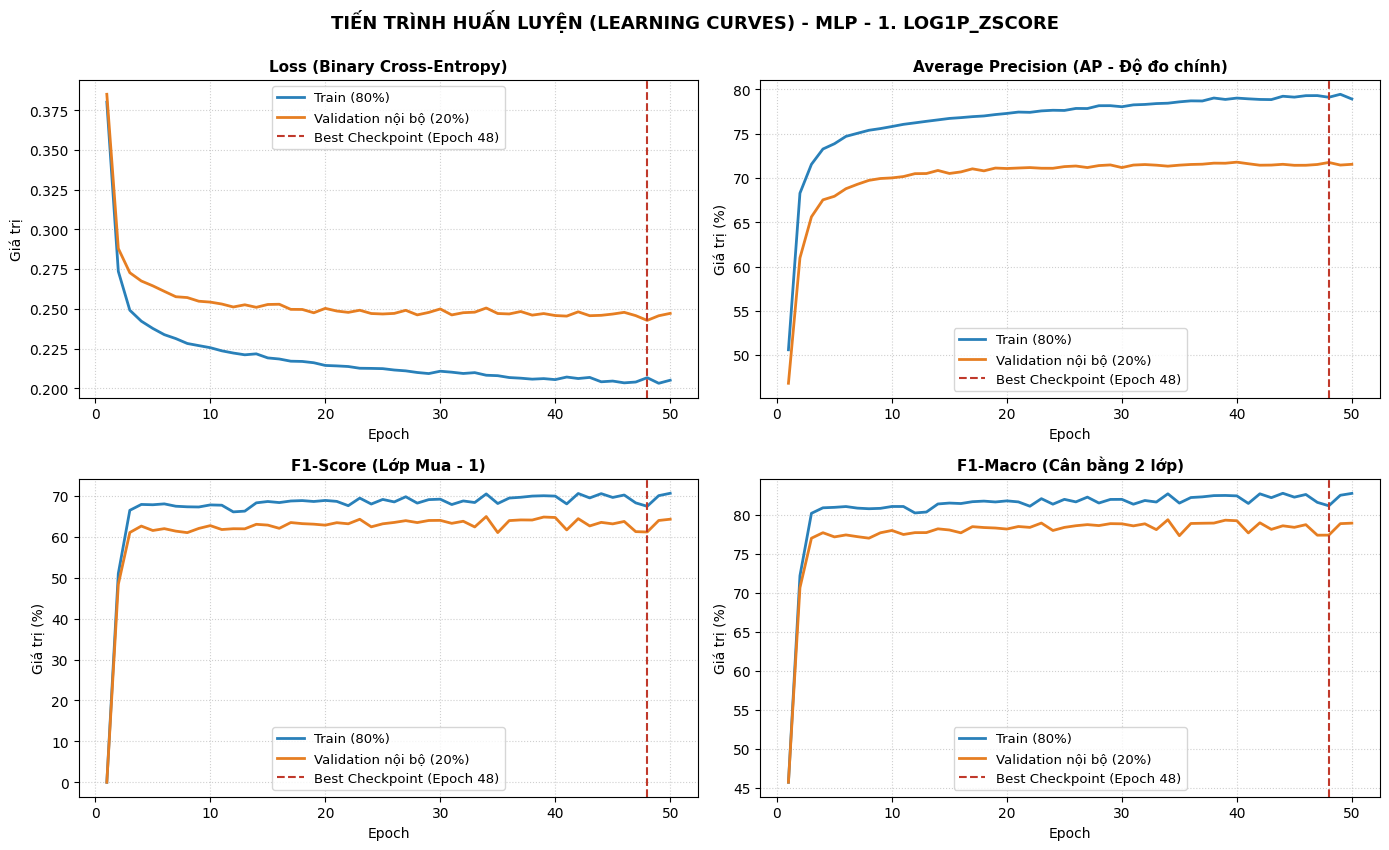

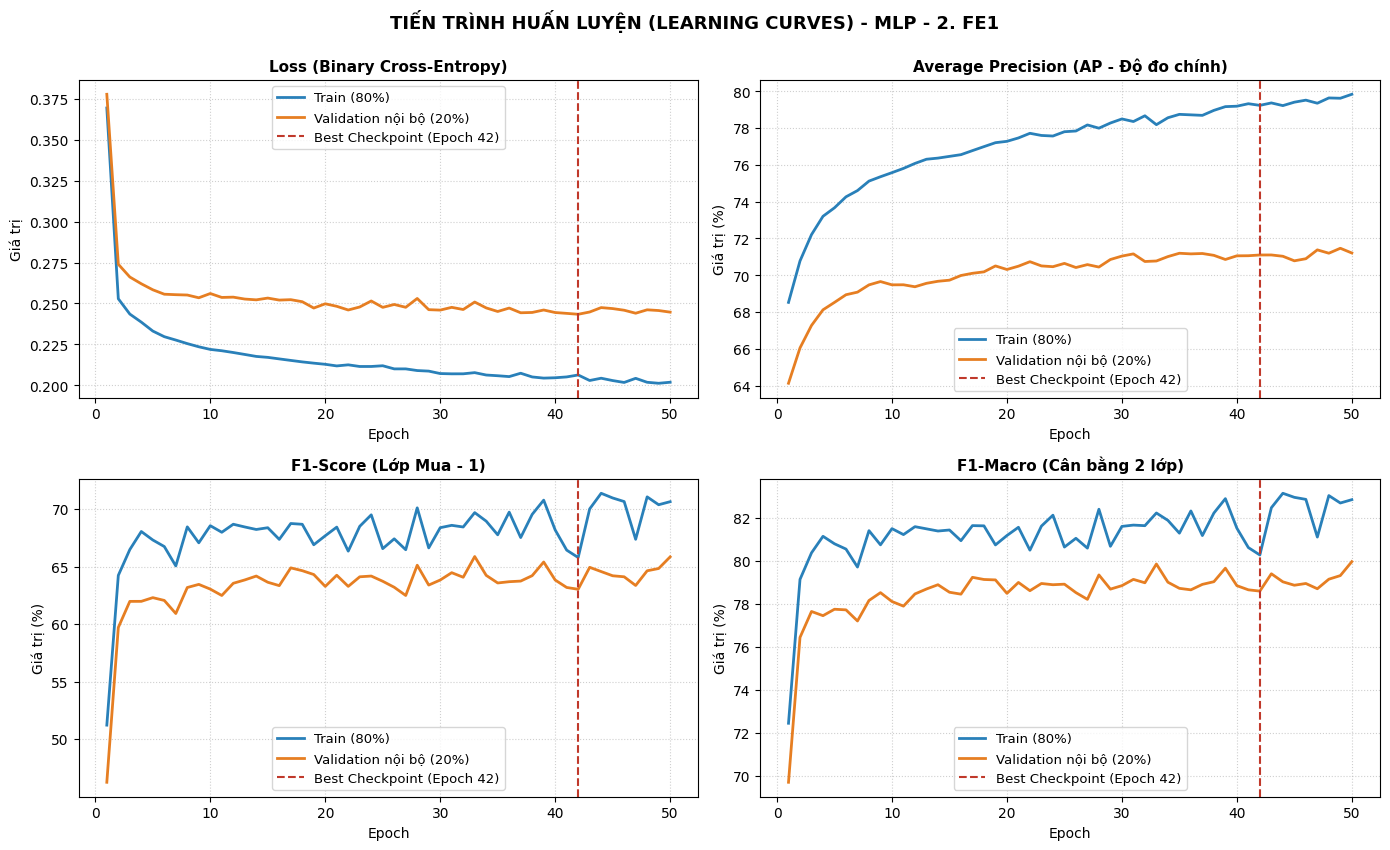

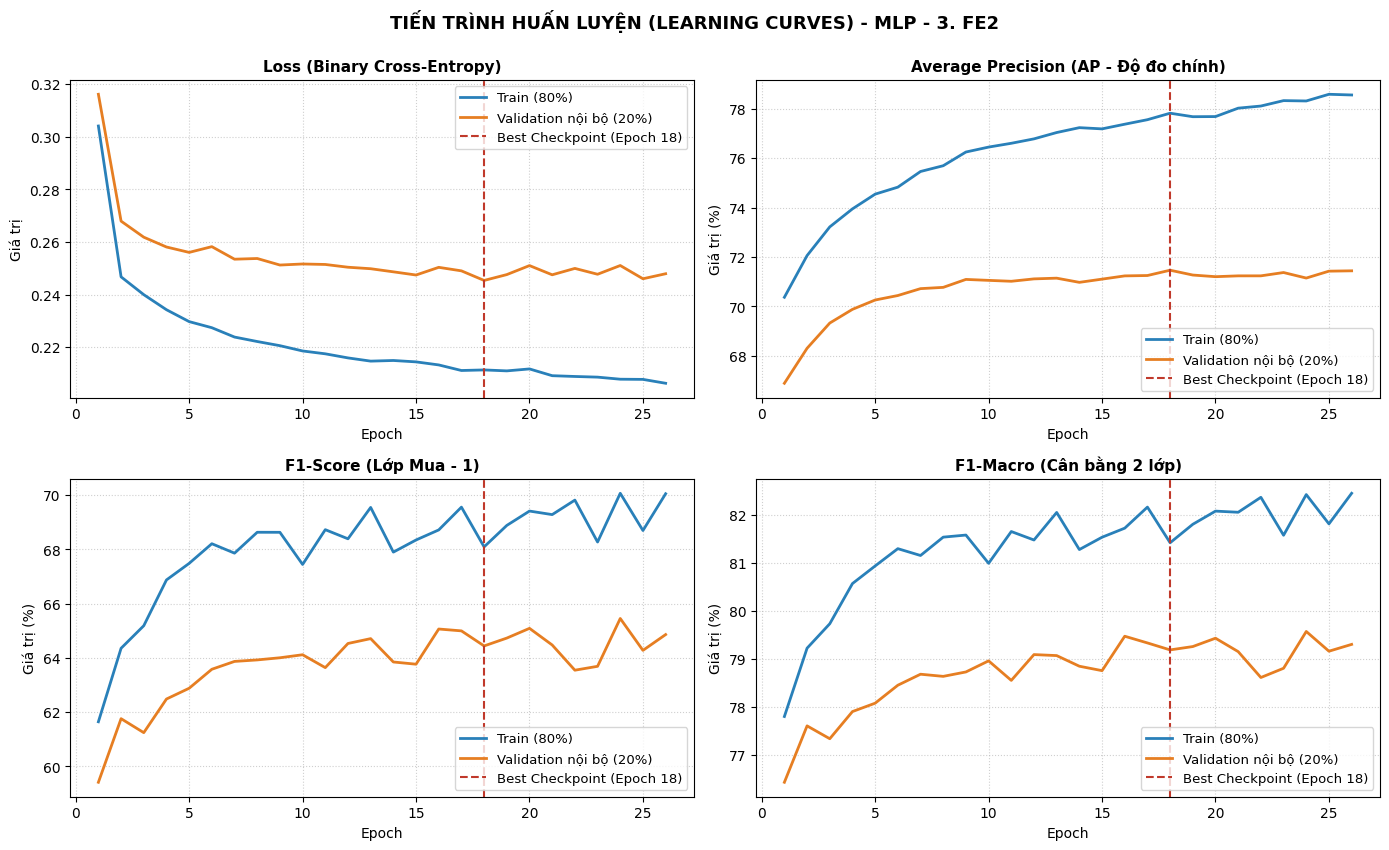

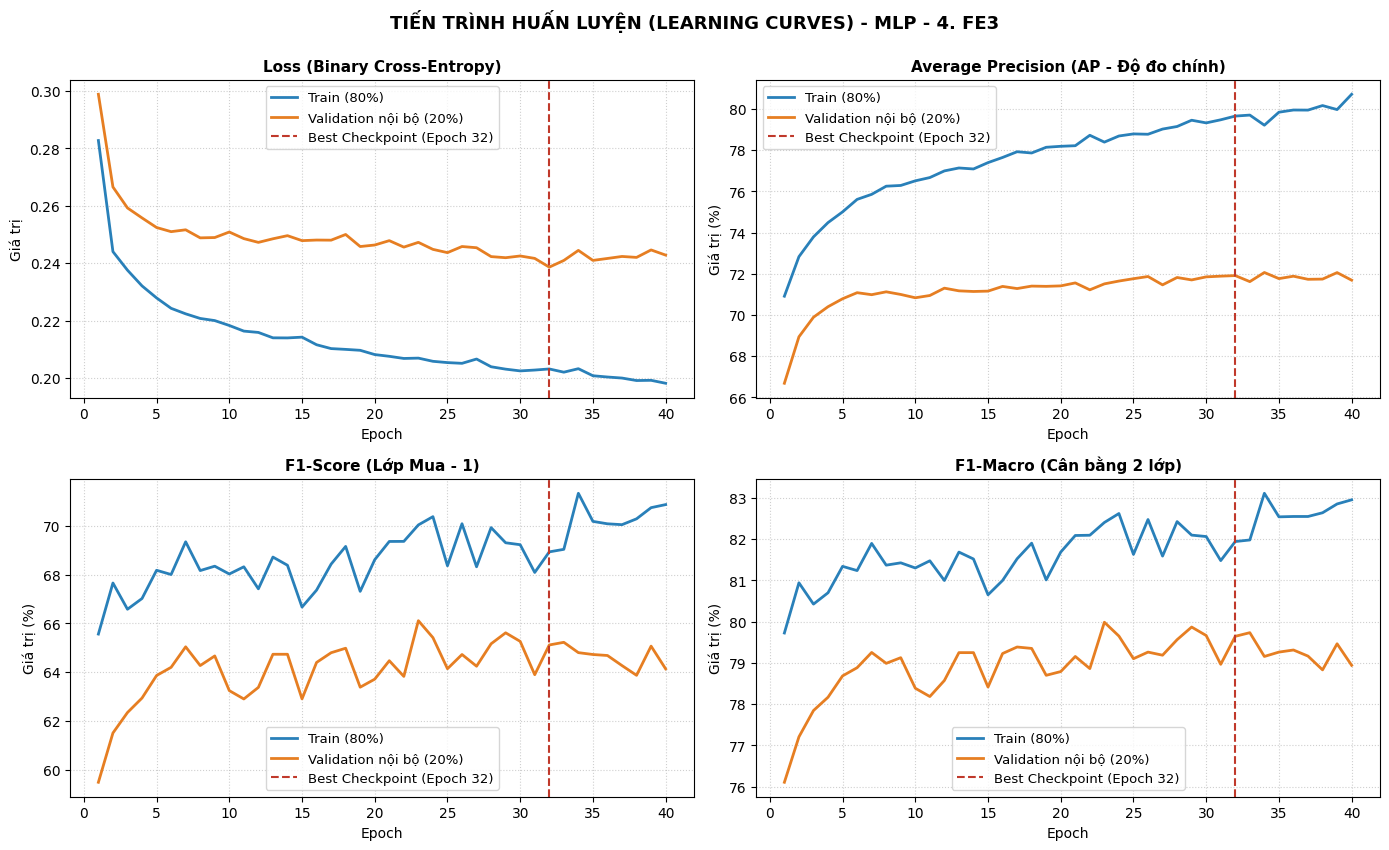

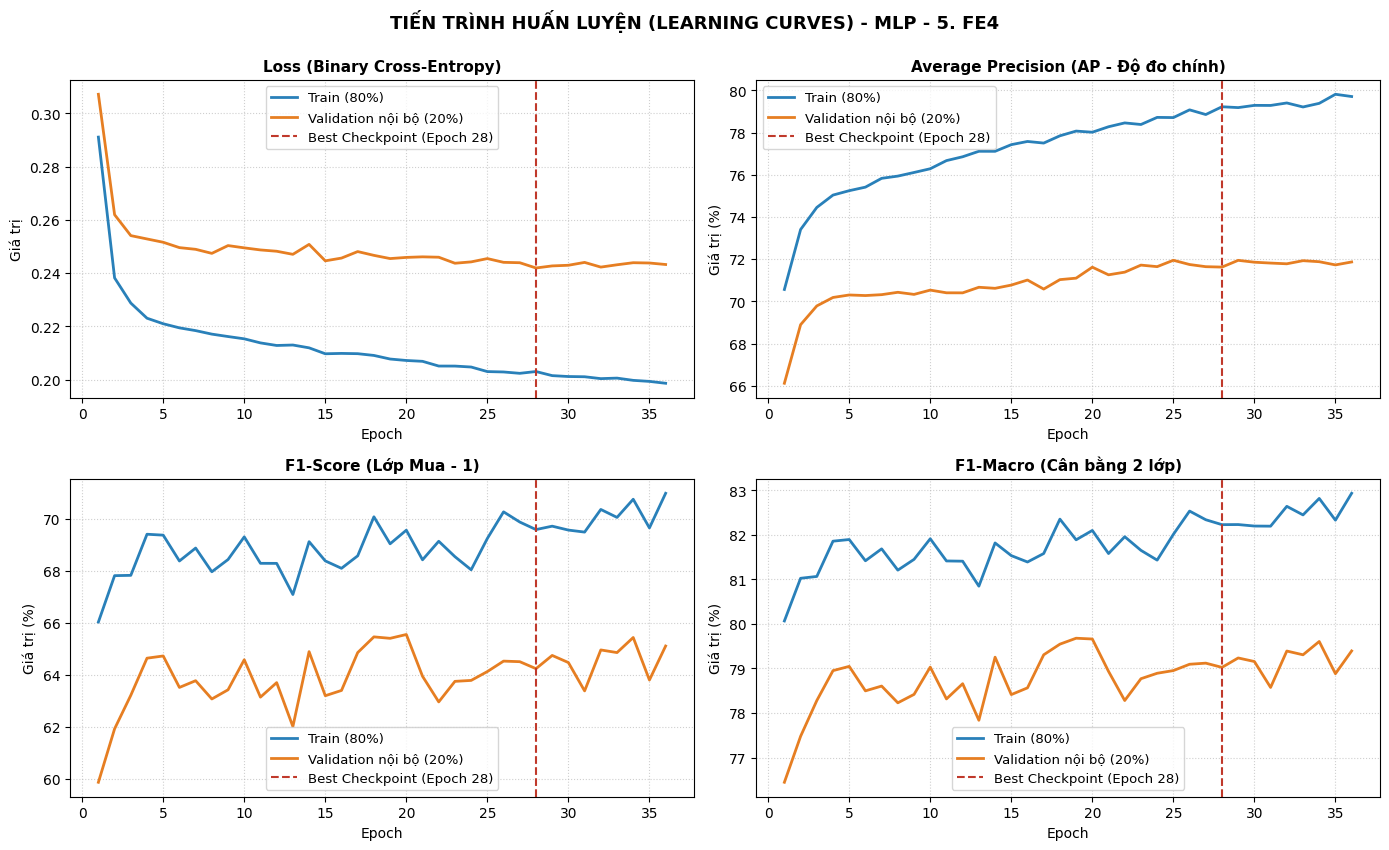

In [8]:
test_results_dict = {}
test_summary_rows = []
mlp_histories = {}

test_mask0 = (X_test['PageValues'] == 0).values
baseline_rate = y_test.mean() * 100
base_cfg_name = list(FEATURE_CONFIGS.keys())[0]

print(f"Đang huấn luyện trên toàn bộ X_train và đánh giá độc lập trên X_test ({len(y_test):,} phiên)...")

for model_name in ['XGBoost', 'LR', 'MLP']:
    base_feats = FEATURE_CONFIGS[base_cfg_name]
    if model_name in ['XGBoost', 'LR']:
        base_pipe = build_pipeline(base_feats, model_name)
        base_pipe.fit(X_train[base_feats], y_train)
        base_proba = base_pipe.predict_proba(X_test[base_feats])[:, 1]
    else: # MLP
        prep_base, model_base, hist_base = train_pytorch_mlp(
            X_train[base_feats], y_train, build_preprocessor(base_feats),
            random_state=RANDOM_STATE, return_history=True, test_size=0.2
        )
        base_proba = predict_proba_mlp(prep_base, model_base, X_test[base_feats])
        mlp_histories[base_cfg_name] = hist_base

    base_test_ap = average_precision_score(y_test, base_proba) * 100

    for cfg_name, feats in FEATURE_CONFIGS.items():
        if model_name in ['XGBoost', 'LR']:
            pipe = build_pipeline(feats, model_name)
            pipe.fit(X_train[feats], y_train)
            proba = pipe.predict_proba(X_test[feats])[:, 1]
        else: # MLP
            prep, model, hist = train_pytorch_mlp(
                X_train[feats], y_train, build_preprocessor(feats),
                random_state=RANDOM_STATE, return_history=True, test_size=0.2
            )
            proba = predict_proba_mlp(prep, model, X_test[feats])
            mlp_histories[cfg_name] = hist

        pred = (proba >= THRESHOLD).astype(int)

        # evaluate_test tự động tính AP, precision, recall, f1 cho 2 lớp và KHÔNG lưu confusion_matrix vào JSON
        test_res = evaluate_test(y_test, proba, threshold=THRESHOLD)
        test_results_dict[(cfg_name, model_name)] = {
            'proba': proba,
            'pred': pred,
            'test_res': test_res
        }

        slug = 'Base_Full17' if ('Base' in cfg_name or 'log1p' in cfg_name) else cfg_name.split('(')[0].replace('.', '').strip().replace(' ', '_')
        log_experiment(
            exp_id=f"exp3_TEST_{slug}_{model_name}",
            model_name=model_name if model_name != 'MLP' else 'MLP (PyTorch)',
            notebook=NOTEBOOK,
            description=f"Exp3 Test | {cfg_name} {model_name}",
            config={'features_count': len(feats), 'features': feats, 'threshold': THRESHOLD},
            cv_results=cv_results_store[(cfg_name, model_name)],
            test_results=test_res
        )

        cur_ap = test_res['ap'] * 100
        diff_ap = cur_ap - base_test_ap
        p1 = test_res['class_1']['precision'] * 100
        r1 = test_res['class_1']['recall'] * 100
        f1_1 = test_res['class_1']['f1_score'] * 100
        f1_0 = test_res['class_0']['f1_score'] * 100
        f1_mac = test_res['f1_macro'] * 100
        ap_0 = average_precision_score(y_test[test_mask0], proba[test_mask0]) * 100

        test_summary_rows.append({
            'Mô hình': model_name if model_name != 'MLP' else 'MLP (PyTorch)',
            'Cấu hình': cfg_name,
            'Số biến': len(feats),
            'Test AP (%)': f"{cur_ap:.2f}",
            f'ΔAP (vs {base_cfg_name})': '-' if cfg_name == base_cfg_name else f"{diff_ap:+.2f}%",
            'Precision (Mua) (%)': f"{p1:.2f}",
            'Recall (Mua) (%)': f"{r1:.2f}",
            'F1 (Mua) (%)': f"{f1_1:.2f}",
            'F1 (Không mua) (%)': f"{f1_0:.2f}",
            'F1 macro (%)': f"{f1_mac:.2f}",
            'Accuracy (%)': f"{test_res['accuracy']*100:.2f}",
            'Test AP (PV = 0) (%)': f"{ap_0:.2f}"
        })

df_test_summary = pd.DataFrame(test_summary_rows)
print(f"\n=== BẢNG TỔNG HỢP KẾT QUẢ TRÊN TẬP TEST HOLD-OUT (Ngưỡng quyết định threshold = {THRESHOLD:.2f}) ===")
display(df_test_summary)

# 1. In Classification Report chi tiết (0 = Không mua, 1 = Mua) cho cấu hình cuối cùng vs cấu hình đầu tiên
final_cfg_name = list(FEATURE_CONFIGS.keys())[-1]
print(f"\n=== CLASSIFICATION REPORT CHI TIẾT TRÊN TẬP TEST (0 = Không mua, 1 = Mua | Threshold = {THRESHOLD:.2f}) ===")
for model_name in ['XGBoost', 'LR', 'MLP']:
    for cfg_name in [base_cfg_name, final_cfg_name]:
        pred = test_results_dict[(cfg_name, model_name)]['pred']
        ap_v = test_results_dict[(cfg_name, model_name)]['test_res']['ap'] * 100
        m_display = model_name if model_name != 'MLP' else 'MLP (PyTorch)'
        print(f"\n--- Mô hình: {m_display} | Cấu hình: {cfg_name} | Test AP: {ap_v:.2f}% ---")
        print(classification_report(y_test, pred, target_names=['0 = Không mua', '1 = Mua'], digits=4, zero_division=0))

# 2. VẼ CONFUSION MATRIX CHO CÁC CẤU HÌNH x 3 MÔ HÌNH TRỰC TIẾP TRONG NOTEBOOK
for model_name, colormap in [('XGBoost', 'Blues'), ('LR', 'Greens'), ('MLP', 'Oranges')]:
    fig_cm, axes_cm = plt.subplots(1, len(FEATURE_CONFIGS), figsize=(22, 4))
    m_display = model_name if model_name != 'MLP' else 'MLP (PyTorch)'
    for idx, (cfg_name, feats) in enumerate(FEATURE_CONFIGS.items()):
        pred = test_results_dict[(cfg_name, model_name)]['pred']
        cm = confusion_matrix(y_test, pred)
        f1_1 = f1_score(y_test, pred, pos_label=1) * 100
        short_name = cfg_name.split('(')[0].strip()
        plot_confusion_matrix(cm, title=f"{model_name}: {short_name}\n(F1 Mua: {f1_1:.2f}%)", threshold=THRESHOLD, ax=axes_cm[idx], cmap=colormap)
    plt.suptitle(f'Ma trận Nhầm lẫn (Confusion Matrix) trên Tập Test - {m_display}', fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

# 3. VẼ PRECISION-RECALL CURVES (STATIC MATPLOTLIB)
COLORS = ['#7F8C8D', '#3498DB', '#F39C12', '#9B59B6', '#E74C3C']

fig_pr, axes_pr = plt.subplots(1, 3, figsize=(22, 6), sharey=True)
for m_idx, model_name in enumerate(['XGBoost', 'LR', 'MLP']):
    ax = axes_pr[m_idx]
    m_display = model_name if model_name != 'MLP' else 'MLP (PyTorch)'
    ax.axhline(baseline_rate / 100, color='gray', linestyle='--', linewidth=1.2, label=f'Tỷ lệ Mua nền ({baseline_rate:.2f}%)')
    for idx, (cfg_name, feats) in enumerate(FEATURE_CONFIGS.items()):
        proba = test_results_dict[(cfg_name, model_name)]['proba']
        prec, rec, _ = precision_recall_curve(y_test, proba)
        ap_val = test_results_dict[(cfg_name, model_name)]['test_res']['ap'] * 100
        lw = 2.5 if idx in [0, len(FEATURE_CONFIGS)-1] else 1.6
        ax.plot(rec, prec, color=COLORS[idx % len(COLORS)], linewidth=lw, label=f"{cfg_name} (AP = {ap_val:.2f}%)")
    ax.set_title(f'Precision-Recall Curves - {m_display}', fontsize=12.5, fontweight='bold')
    ax.set_xlabel('Recall (Mua)', fontsize=11)
    if m_idx == 0:
        ax.set_ylabel('Precision (Mua)', fontsize=11)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='lower left', fontsize=9.0)
plt.suptitle('Khảo sát Đường cong Precision-Recall (PR Curve) trên Tập Test Hold-out', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 4. VẼ TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) CHO CÁC CẤU HÌNH PYTORCH MLP
print("\n" + "="*80)
print("TIẾN TRÌNH HUẤN LUYỆN (LEARNING CURVES) - PYTORCH MLP TRÊN TẬP TRAIN & VAL NỘI BỘ:")
print("="*80)
for cfg_name, hist in mlp_histories.items():
    plot_learning_curves(hist, model_title=f"MLP - {cfg_name}")


## 6. Bảng Tổng kết Thực nghiệm từ `logger.py`

In [9]:
cv_df = load_experiments_df(view='cv')
te_df = load_experiments_df(view='test')

print("=== 1. TỔNG HỢP CROSS-VALIDATION (EXP 3 - BASE 17 & FE1 ĐẾN FE4) ===")
display(cv_df[cv_df['Notebook'] == NOTEBOOK])

print("=== 2. TỔNG HỢP KIỂM CHỨNG TRÊN TẬP TEST (EXP 3 - BASE 17 & FE1 ĐẾN FE4) ===")
display(te_df[te_df['Experiment ID'].str.contains('exp3_TEST')])

=== 1. TỔNG HỢP CROSS-VALIDATION (EXP 3 - BASE 17 & FE1 ĐẾN FE4) ===


,Experiment ID,Model,Notebook,CV AP (%),CV Precision (Mua) (%),CV Recall (Mua) (%),CV F1 (Mua) (%),CV Precision (Không mua) (%),CV Recall (Không mua) (%),CV F1 (Không mua) (%),CV F1 Macro (%)
9,exp3_Base_Full17_LR,LR,exp3_feature_generation.ipynb,68.15 ± 2.07,70.40 ± 2.64,55.11 ± 2.12,61.79 ± 1.82,92.01 ± 0.35,95.69 ± 0.56,93.81 ± 0.33,77.80 ± 0.92
10,exp3_Base_Full17_XGBoost,XGBoost,exp3_feature_generation.ipynb,71.70 ± 1.97,69.67 ± 3.07,58.19 ± 1.60,63.37 ± 1.50,92.48 ± 0.26,95.27 ± 0.71,93.86 ± 0.36,78.61 ± 0.77
11,exp3_Base_Full17_MLP,MLP (PyTorch),exp3_feature_generation.ipynb,73.59 ± 1.52,71.71 ± 2.62,58.78 ± 2.57,64.53 ± 1.59,92.61 ± 0.40,95.67 ± 0.67,94.12 ± 0.29,79.33 ± 0.81
12,exp3_2_FE1_LR,LR,exp3_feature_generation.ipynb,71.33 ± 2.24,71.37 ± 2.69,58.11 ± 2.50,64.03 ± 2.24,92.50 ± 0.43,95.67 ± 0.52,94.06 ± 0.38,79.05 ± 1.14
13,exp3_2_FE1_XGBoost,XGBoost,exp3_feature_generation.ipynb,71.18 ± 1.90,69.94 ± 2.78,58.32 ± 2.93,63.53 ± 2.02,92.51 ± 0.47,95.33 ± 0.72,93.90 ± 0.36,78.72 ± 1.03
14,exp3_2_FE1_MLP,MLP (PyTorch),exp3_feature_generation.ipynb,74.45 ± 1.53,72.16 ± 2.42,60.81 ± 3.50,65.90 ± 1.89,92.95 ± 0.55,95.62 ± 0.72,94.26 ± 0.27,80.08 ± 0.95
15,exp3_3_FE2_LR,LR,exp3_feature_generation.ipynb,71.99 ± 1.99,72.15 ± 3.17,57.91 ± 2.55,64.21 ± 2.38,92.48 ± 0.44,95.84 ± 0.62,94.13 ± 0.42,79.17 ± 1.21
16,exp3_3_FE2_XGBoost,XGBoost,exp3_feature_generation.ipynb,72.08 ± 1.77,69.56 ± 2.75,58.65 ± 2.40,63.59 ± 1.74,92.56 ± 0.39,95.22 ± 0.70,93.87 ± 0.35,78.73 ± 0.89
17,exp3_3_FE2_MLP,MLP (PyTorch),exp3_feature_generation.ipynb,74.39 ± 1.34,72.78 ± 3.78,58.76 ± 3.98,64.82 ± 1.72,92.63 ± 0.60,95.85 ± 1.04,94.20 ± 0.33,79.51 ± 0.88
18,exp3_4_FE3_LR,LR,exp3_feature_generation.ipynb,72.24 ± 1.98,72.22 ± 3.12,58.35 ± 2.75,64.49 ± 2.22,92.55 ± 0.45,95.82 ± 0.68,94.15 ± 0.39,79.32 ± 1.13


=== 2. TỔNG HỢP KIỂM CHỨNG TRÊN TẬP TEST (EXP 3 - BASE 17 & FE1 ĐẾN FE4) ===


,Experiment ID,Model,Notebook,Ngưỡng (Threshold),Test AP (%),Accuracy (%),Test F1 (Không mua) (%),Test F1 (Mua) (%),Test F1 Macro (%),Test Precision (Mua) (%),Test Recall (Mua) (%),Test Precision (Không mua) (%),Test Recall (Không mua) (%)
24,exp3_TEST_Base_Full17_XGBoost,XGBoost,exp3_feature_generation.ipynb,0.5,72.42,89.31,93.73,63.60,78.67,68.06,59.69,92.69,94.80
25,exp3_TEST_2_FE1_XGBoost,XGBoost,exp3_feature_generation.ipynb,0.5,71.34,89.72,93.96,65.38,79.67,69.10,62.04,93.09,94.85
26,exp3_TEST_3_FE2_XGBoost,XGBoost,exp3_feature_generation.ipynb,0.5,72.40,89.68,93.94,65.19,79.57,69.01,61.78,93.04,94.85
27,exp3_TEST_4_FE3_XGBoost,XGBoost,exp3_feature_generation.ipynb,0.5,73.49,90.33,94.34,66.95,80.64,71.99,62.57,93.22,95.48
28,exp3_TEST_5_FE4_XGBoost,XGBoost,exp3_feature_generation.ipynb,0.5,71.32,89.84,94.05,65.27,79.66,70.18,60.99,92.94,95.19
29,exp3_TEST_Base_Full17_LR,LR,exp3_feature_generation.ipynb,0.5,69.52,90.00,94.17,65.04,79.61,71.84,59.42,92.71,95.68
30,exp3_TEST_2_FE1_LR,LR,exp3_feature_generation.ipynb,0.5,72.35,90.17,94.25,66.10,80.18,71.78,61.26,93.00,95.53
31,exp3_TEST_3_FE2_LR,LR,exp3_feature_generation.ipynb,0.5,73.10,90.09,94.21,65.62,79.92,71.74,60.47,92.87,95.58
32,exp3_TEST_4_FE3_LR,LR,exp3_feature_generation.ipynb,0.5,73.53,90.13,94.23,65.91,80.07,71.69,60.99,92.96,95.53
33,exp3_TEST_5_FE4_LR,LR,exp3_feature_generation.ipynb,0.5,74.40,90.58,94.51,66.86,80.68,74.36,60.73,92.95,96.11


## 7. Biểu đồ Đường Tiến trình Đối đầu Giữa 3 Mô hình: XGBoost vs. Logistic Regression vs. MLP (Từ `Raw OHE (Baseline)` $\rightarrow$ `StandardScaler` $\rightarrow$ `Log1p + StandardScaler` $\rightarrow$ `FE1` $\rightarrow$ `FE4`)

- Trực quan hóa xuyên suốt lộ trình thực nghiệm theo đúng thứ tự:
  1. **`Raw OHE (Baseline)`** *(Exp 0 - 17 biến thô)*
  2. **`StandardScaler`** *(Exp 1 - 17 biến chuẩn hóa)*
  3. **`Log1p + StandardScaler`** *(Base 17 - 17 biến xử lý lệch)*
  4. **`FE1 (Core PV Density)`** *(20 biến)*
  5. **`FE2 (Value vs. Friction)`** *(22 biến)*
  6. **`FE3 (Session Structure)`** *(24 biến)*
  7. **`FE4 (Seasonality Context)`** *(26 biến)*
- **Bố cục đối đầu trực quan**:
  - **Đồ thị trên**: **Độ đo chính Average Precision (AP)** – So sánh trực tiếp đường cong AP của XGBoost vs. Logistic Regression vs. MLP qua từng cấu hình.
  - **Đồ thị dưới**: **Chỉ số Cân bằng Lớp Mua: F1 (Mua)** tại ngưỡng mặc định `threshold = 0.50`.


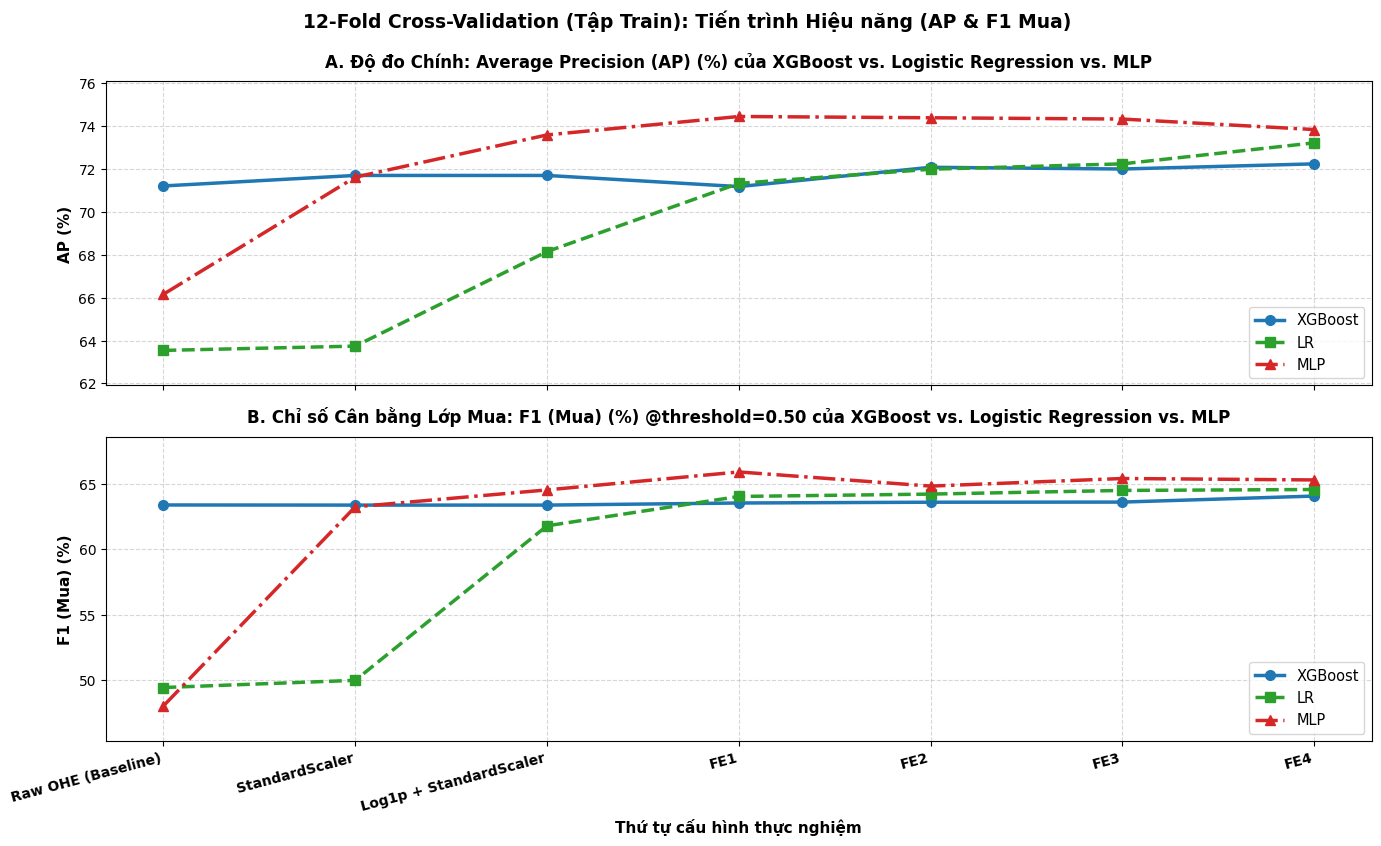

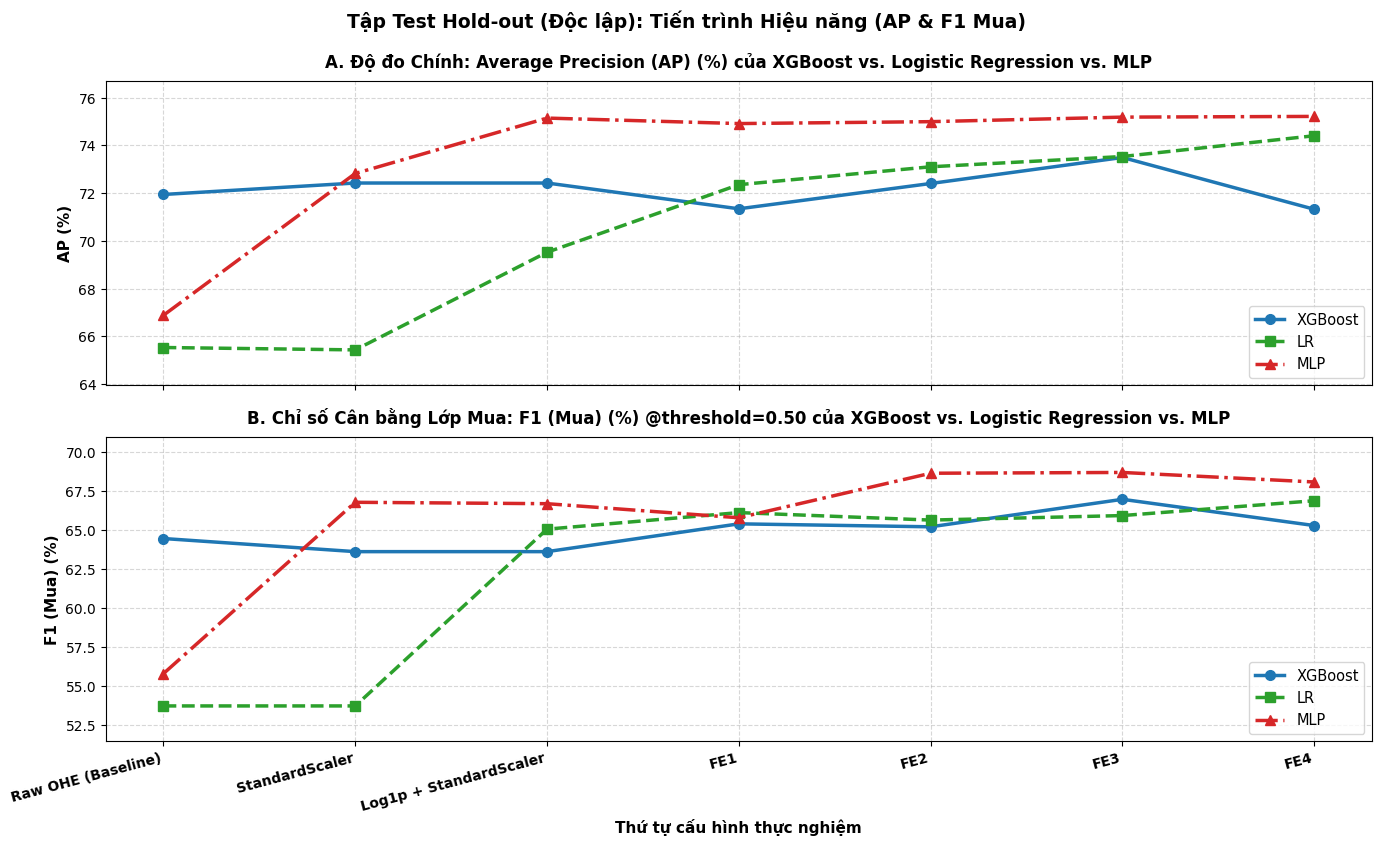

In [10]:
with open('experiment_results.json', 'r', encoding='utf-8') as f:
    exp_data = json.load(f)

config_map_cv = {
    'Raw OHE (Baseline)': {'XGBoost': 'exp0_baseline_xgb', 'LR': 'exp0_baseline_logistic', 'MLP': 'exp0_baseline_mlp'},
    'StandardScaler': {'XGBoost': 'exp1_tn1_standard_scaler_xgb', 'LR': 'exp1_tn1_standard_scaler_lr', 'MLP': 'exp1_tn1_standard_scaler_mlp'},
    'Log1p + StandardScaler': {'XGBoost': 'exp3_Base_Full17_XGBoost', 'LR': 'exp3_Base_Full17_LR', 'MLP': 'exp3_Base_Full17_MLP'},
    'FE1': {'XGBoost': 'exp3_2_FE1_XGBoost', 'LR': 'exp3_2_FE1_LR', 'MLP': 'exp3_2_FE1_MLP'},
    'FE2': {'XGBoost': 'exp3_3_FE2_XGBoost', 'LR': 'exp3_3_FE2_LR', 'MLP': 'exp3_3_FE2_MLP'},
    'FE3': {'XGBoost': 'exp3_4_FE3_XGBoost', 'LR': 'exp3_4_FE3_LR', 'MLP': 'exp3_4_FE3_MLP'},
    'FE4': {'XGBoost': 'exp3_5_FE4_XGBoost', 'LR': 'exp3_5_FE4_LR', 'MLP': 'exp3_5_FE4_MLP'},
}

config_map_test = {
    'Raw OHE (Baseline)': {'XGBoost': 'exp0_baseline_xgb', 'LR': 'exp0_baseline_logistic', 'MLP': 'exp0_baseline_mlp'},
    'StandardScaler': {'XGBoost': 'exp1_tn1_standard_scaler_xgb', 'LR': 'exp1_tn1_standard_scaler_lr', 'MLP': 'exp1_tn1_standard_scaler_mlp'},
    'Log1p + StandardScaler': {'XGBoost': 'exp3_TEST_Base_Full17_XGBoost', 'LR': 'exp3_TEST_Base_Full17_LR', 'MLP': 'exp3_TEST_Base_Full17_MLP'},
    'FE1': {'XGBoost': 'exp3_TEST_2_FE1_XGBoost', 'LR': 'exp3_TEST_2_FE1_LR', 'MLP': 'exp3_TEST_2_FE1_MLP'},
    'FE2': {'XGBoost': 'exp3_TEST_3_FE2_XGBoost', 'LR': 'exp3_TEST_3_FE2_LR', 'MLP': 'exp3_TEST_3_FE2_MLP'},
    'FE3': {'XGBoost': 'exp3_TEST_4_FE3_XGBoost', 'LR': 'exp3_TEST_4_FE3_LR', 'MLP': 'exp3_TEST_4_FE3_MLP'},
    'FE4': {'XGBoost': 'exp3_TEST_5_FE4_XGBoost', 'LR': 'exp3_TEST_5_FE4_LR', 'MLP': 'exp3_TEST_5_FE4_MLP'},
}

model_styles = {
    'XGBoost': {'color': '#1f77b4', 'marker': 'o', 'linestyle': '-', 'lw': 2.5},
    'LR':      {'color': '#2ca02c', 'marker': 's', 'linestyle': '--', 'lw': 2.5},
    'MLP':     {'color': '#d62728', 'marker': '^', 'linestyle': '-.', 'lw': 2.5}
}

# 1. Trích xuất dữ liệu 12-Fold CV
cv_rows = []
for cfg_label, m_dict in config_map_cv.items():
    for model_name, exp_key in m_dict.items():
        if exp_key in exp_data and 'cv_results' in exp_data[exp_key]:
            res = exp_data[exp_key]['cv_results']
            c1 = res.get('class_1', {})
            ap = res.get('ap_mean', 0) * 100
            p1 = c1.get('precision_mean', 0) * 100
            r1 = c1.get('recall_mean', 0) * 100
            f1_1 = c1.get('f1_mean', 0) * 100
            cv_rows.append({
                'Model': model_name, 'Config': cfg_label,
                'AP': ap, 'Precision (Mua)': p1, 'Recall (Mua)': r1, 'F1 (Mua)': f1_1
            })
df_chart_cv = pd.DataFrame(cv_rows)

# 2. Trích xuất dữ liệu Tập Test Hold-out
test_rows = []
for cfg_label, m_dict in config_map_test.items():
    for model_name, exp_key in m_dict.items():
        if exp_key in exp_data and 'test_results' in exp_data[exp_key]:
            res = exp_data[exp_key]['test_results']
            c1 = res.get('class_1', {})
            ap = res.get('ap', 0) * 100
            p1 = c1.get('precision', 0) * 100
            r1 = c1.get('recall', 0) * 100
            f1_1 = c1.get('f1_score', 0) * 100
            test_rows.append({
                'Model': model_name, 'Config': cfg_label,
                'AP': ap, 'Precision (Mua)': p1, 'Recall (Mua)': r1, 'F1 (Mua)': f1_1
            })
df_chart_test = pd.DataFrame(test_rows)

# HÀM VẼ ĐỐI ĐẦU 3 MÔ HÌNH
def plot_head_to_head(df_data, title_prefix, file_name):
    fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)
    configs = df_data['Config'].unique()
    x = range(len(configs))

    # --- SUBPLOT 1: ĐỘ ĐO CHÍNH AVERAGE PRECISION (AP) ---
    ax_ap = axes[0]
    all_ap = df_data['AP'].values if len(df_data) > 0 else np.array([0])
    y_min_ap, y_max_ap = all_ap.min(), all_ap.max()
    margin_ap = max((y_max_ap - y_min_ap) * 0.15, 1.0)

    for model in ['XGBoost', 'LR', 'MLP']:
        sub = df_data[df_data['Model'] == model].reset_index(drop=True)
        if len(sub) > 0:
            style = model_styles[model]
            ax_ap.plot(x[:len(sub)], sub['AP'], label=model, color=style['color'],
                       marker=style['marker'], linestyle=style['linestyle'],
                       linewidth=style['lw'], markersize=7)

    ax_ap.set_title("A. Độ đo Chính: Average Precision (AP) (%) của XGBoost vs. Logistic Regression vs. MLP",
                    fontsize=12, fontweight='bold', pad=10)
    ax_ap.set_ylabel("AP (%)", fontsize=11, fontweight='bold')
    ax_ap.set_ylim(y_min_ap - margin_ap, y_max_ap + margin_ap)
    ax_ap.grid(True, linestyle='--', alpha=0.5)
    ax_ap.legend(loc='lower right', frameon=True, fontsize=10.5)

    # --- SUBPLOT 2: F1 (MUA) TẠI THRESHOLD = 0.50 ---
    ax_f1 = axes[1]
    all_f1 = df_data['F1 (Mua)'].values if len(df_data) > 0 else np.array([0])
    y_min_f1, y_max_f1 = all_f1.min(), all_f1.max()
    margin_f1 = max((y_max_f1 - y_min_f1) * 0.15, 1.5)

    for model in ['XGBoost', 'LR', 'MLP']:
        sub = df_data[df_data['Model'] == model].reset_index(drop=True)
        if len(sub) > 0:
            style = model_styles[model]
            ax_f1.plot(x[:len(sub)], sub['F1 (Mua)'], label=model, color=style['color'],
                       marker=style['marker'], linestyle=style['linestyle'],
                       linewidth=style['lw'], markersize=7)

    ax_f1.set_title("B. Chỉ số Cân bằng Lớp Mua: F1 (Mua) (%) @threshold=0.50 của XGBoost vs. Logistic Regression vs. MLP",
                    fontsize=12, fontweight='bold', pad=10)
    ax_f1.set_ylabel("F1 (Mua) (%)", fontsize=11, fontweight='bold')
    ax_f1.set_ylim(y_min_f1 - margin_f1, y_max_f1 + margin_f1)
    ax_f1.grid(True, linestyle='--', alpha=0.5)
    ax_f1.legend(loc='lower right', frameon=True, fontsize=10.5)

    ax_f1.set_xticks(range(len(configs)))
    ax_f1.set_xticklabels(configs, rotation=15, ha='right', fontsize=10, fontweight='bold')
    ax_f1.set_xlabel("Thứ tự cấu hình thực nghiệm", fontsize=11, fontweight='bold')

    plt.suptitle(f"{title_prefix}: Tiến trình Hiệu năng (AP & F1 Mua)", fontsize=13.5, fontweight='bold', y=0.99)
    plt.tight_layout()
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    plt.show()

# Vẽ biểu đồ 12-Fold CV
plot_head_to_head(df_chart_cv, "12-Fold Cross-Validation (Tập Train)", "exp3_metrics_progression_cv.png")

# Vẽ biểu đồ Test Hold-out
plot_head_to_head(df_chart_test, "Tập Test Hold-out (Độc lập)", "exp3_metrics_progression.png")
